# ส่วนที่ 6: กรณีศึกษา (Case Study for Quant Finance Project)
## การวิเคราะห์เชิงปริมาณและการสร้างกลยุทธ์การลงทุนด้วย Python สำหรับพอร์ตจำลองเชิง Quant Finance

**สมาชิกกลุ่ม**
1. ชื่อ–สกุล ............................ รหัสนักศึกษา ..............
2. ชื่อ–สกุล ............................ รหัสนักศึกษา ..............
3. ชื่อ–สกุล ............................ รหัสนักศึกษา ..............

---
### ขอบเขตข้อมูล (Dataset & Scope)
คัดเลือกหุ้นจาก 4 กลุ่มอุตสาหกรรมของ SET กลุ่มละ 4 ตัว (รวม 16 ตัว) แล้วเลือกตัวแทนกลุ่มละ 1 ตัวเพื่อสร้างพอร์ต

| กลุ่มอุตสาหกรรม | หุ้นที่วิเคราะห์ | ตัวแทนพอร์ต |
|---|---|---|
| การเงินและธนาคาร (Finance & Banking) | KBANK, BBL, SCB, TTB | **KBANK** |
| สินค้าอุปโภคบริโภค (Consumer & Retail) | CPALL, CPN, BJC, CPAXT | **CPALL** |
| พลังงานและสาธารณูปโภค (Energy & Utilities) | OR, PTT, PTTEP, GPSC | **OR** |
| ขนส่งและโลจิสติกส์ (Transportation & Logistics) | AOT, BEM, BTS, AAV | **AOT** |

> **หมายเหตุ**
> - กลุ่มเทคโนโลยีในโจทย์ถูกแทนด้วยกลุ่ม **ขนส่งและโลจิสติกส์** เพื่อให้ครอบคลุม AOT ซึ่งเป็นหุ้นที่กลุ่มเลือก
> - MAKRO ถูกเปลี่ยนชื่อเป็น **CPAXT** (CP Axtra) ตั้งแต่ปี 2566 จึงใช้ `CPAXT.BK` แทน
> - OR ถูกจัดในกลุ่มพลังงาน (ธุรกิจค้าปลีกน้ำมัน) แทน BGRIM

**แหล่งข้อมูล:** yfinance (Symbol + `.BK`), ราคาย้อนหลัง `period="1y"`, ข้อมูลพื้นฐานจาก `yf.Ticker().info`, `financials`, `balance_sheet`

### 0. ติดตั้งและนำเข้าไลบรารี (Setup)

In [1]:
# !pip install yfinance pandas numpy matplotlib seaborn scipy   # รันครั้งแรกหากยังไม่มีไลบรารี
import warnings                         # ไว้ปิด warning ที่ไม่จำเป็น
warnings.filterwarnings("ignore")       # ปิด warning ไม่ให้รกตอนรัน

import numpy as np                      # คำนวณตัวเลข / matrix
import pandas as pd                     # จัดการข้อมูลเป็นตาราง DataFrame
import matplotlib.pyplot as plt         # วาดกราฟหลัก
import seaborn as sns                   # วาดกราฟสวย ๆ เช่น heatmap, barplot
import yfinance as yf                   # ดึงข้อมูลหุ้นจาก Yahoo Finance
from scipy.optimize import minimize     # ใช้หาน้ำหนักพอร์ตที่ดีที่สุด (optimization)
from scipy.stats import norm            # ใช้หาค่า z ของการแจกแจงปกติ (ใช้ตอนคำนวณ VaR)

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")   # ให้ตารางแสดงทศนิยม 4 ตำแหน่ง
pd.set_option("display.width", 160)                            # ขยายความกว้างตารางตอนแสดงผล
sns.set_theme(style="whitegrid", palette="deep")               # ตั้งธีมกราฟให้เป็นพื้นขาวมีเส้นกริด
plt.rcParams["figure.dpi"] = 110                               # เพิ่มความคมชัดของกราฟ

### กำหนดค่าพารามิเตอร์ (Configuration)
- **RF** (Risk-free rate): อัตราผลตอบแทนพันธบัตรรัฐบาลไทย ใช้ 2.0% ต่อปี (ปรับได้ตามข้อมูล ThaiBMA ล่าสุด)
- **KE** (Cost of Equity / Required return): 9.0% ต่อปี ≈ RF + Equity Risk Premium ของตลาดไทย
- **G** (Long-term growth): 3.0% ต่อปี ใช้ใน DDM และ Justified P/BV
- **TRADING_DAYS** = 252 วันทำการต่อปี

In [2]:
# แบ่งหุ้นเป็น 4 กลุ่มอุตสาหกรรม กลุ่มละ 4 ตัว
SECTORS = {
    "Finance & Banking":        ["KBANK", "BBL", "SCB", "TTB"],     # กลุ่มธนาคาร
    "Consumer & Retail":        ["CPALL", "CPN", "BJC", "CPAXT"],   # กลุ่มค้าปลีก/อุปโภคบริโภค
    "Energy & Utilities":       ["OR", "PTT", "PTTEP", "GPSC"],     # กลุ่มพลังงาน
    "Transportation":           ["AOT", "BEM", "BTS", "AAV"],       # กลุ่มขนส่ง (ใช้แทนกลุ่ม Tech)
}
PORTFOLIO = ["KBANK", "CPALL", "OR", "AOT"]   # ตัวแทนที่กลุ่มเลือก (กลุ่มละ 1 ตัว)

RF, KE, G = 0.02, 0.09, 0.03   # risk-free 2%, ผลตอบแทนที่ต้องการ 9%, อัตราเติบโตระยะยาว 3%
TRADING_DAYS = 252             # 1 ปีมีวันทำการประมาณ 252 วัน
N_SIMULATIONS = 10_000         # จำนวนพอร์ตที่จะสุ่มใน Monte Carlo
SEED = 42                      # fix seed ไว้ รันกี่รอบก็ได้ผลสุ่มเหมือนเดิม

TICKERS = [t for ts in SECTORS.values() for t in ts]              # รวมหุ้นทุกกลุ่มเป็น list เดียว (16 ตัว)
SECTOR_OF = {t: s for s, ts in SECTORS.items() for t in ts}       # dict ไว้ดูว่าหุ้นแต่ละตัวอยู่กลุ่มไหน
yf_sym = lambda t: f"{t}.BK"                                      # หุ้นไทยใน yfinance ต้องเติม .BK ต่อท้าย
print(f"จำนวนหุ้นทั้งหมด: {len(TICKERS)} ตัว ->", TICKERS)          # เช็กว่าได้ครบ 16 ตัว

จำนวนหุ้นทั้งหมด: 16 ตัว -> ['KBANK', 'BBL', 'SCB', 'TTB', 'CPALL', 'CPN', 'BJC', 'CPAXT', 'OR', 'PTT', 'PTTEP', 'GPSC', 'AOT', 'BEM', 'BTS', 'AAV']


---
## ภารกิจที่ 1: ดึงข้อมูลราคาปิดย้อนหลังของหุ้นแต่ละกลุ่มจาก yFinance
ใช้ `yf.download()` ดึงราคาย้อนหลัง 1 ปี (`auto_adjust=True` ปรับราคาตามเงินปันผลและการแตกพาร์ เพื่อให้ผลตอบแทนสะท้อนผลตอบแทนรวม)

In [3]:
# ดึงราคาย้อนหลัง 1 ปีของหุ้นทั้ง 16 ตัวพร้อมกันทีเดียว
raw = yf.download([yf_sym(t) for t in TICKERS], period="1y", auto_adjust=True, progress=False)
# เอาเฉพาะราคาปิด แล้วตัด .BK ออกจากชื่อคอลัมน์ให้อ่านง่าย เรียงตามลำดับใน TICKERS
prices = raw["Close"].rename(columns=lambda c: c.replace(".BK", ""))[TICKERS]

print("ขนาดข้อมูลก่อนทำความสะอาด:", prices.shape)      # (จำนวนวัน, จำนวนหุ้น)
print("ค่าว่าง (Missing values) ต่อหุ้น:")
print(prices.isna().sum().to_frame("missing").T)       # นับว่าแต่ละหุ้นมีค่าว่างกี่วัน

# Data cleaning: ตัดแถวที่ทุกตัวเป็น NaN (เช่น วันที่ตลาดยังไม่ปิด) แล้ว forward-fill วันที่หุ้นบางตัวไม่มีการซื้อขาย
prices = prices.dropna(how="all").ffill().dropna()
print(f"\nหลังทำความสะอาด: {prices.shape[0]} วันทำการ ตั้งแต่ {prices.index[0].date()} ถึง {prices.index[-1].date()}")
prices.tail()   # ดู 5 วันล่าสุด

ขนาดข้อมูลก่อนทำความสะอาด: (242, 16)
ค่าว่าง (Missing values) ต่อหุ้น:
Ticker   KBANK  BBL  SCB  TTB  CPALL  CPN  BJC  CPAXT  OR  PTT  PTTEP  GPSC  AOT  BEM  BTS  AAV
missing      1    1    1    1      1    1    1      1   1    1      1     1    1    1    1    1

หลังทำความสะอาด: 241 วันทำการ ตั้งแต่ 2025-11-05 ถึง 2026-11-04


Ticker,KBANK,BBL,SCB,TTB,CPALL,CPN,BJC,CPAXT,OR,PTT,PTTEP,GPSC,AOT,BEM,BTS,AAV
Date,,,,,,,,,,,,,,,,
2026-10-29,250.0000,187.5000,153.5000,2.7800,44.2500,64.5000,20.0000,14.1000,12.5000,42.2500,163.5000,49.7500,60.0000,6.2500,1.8900,0.7700
2026-10-30,246.0000,185.0000,152.5000,2.7400,43.7500,63.7500,19.7000,14.0000,12.5000,42.0000,165.0000,49.2500,59.7500,6.2000,1.8400,0.7300
2026-11-02,242.0000,182.5000,151.0000,2.7000,43.7500,64.7500,20.2000,14.0000,12.5000,41.0000,158.0000,49.0000,60.0000,6.2000,1.8300,0.7300
2026-11-03,243.0000,182.0000,151.0000,2.6800,44.0000,64.7500,19.7000,14.0000,12.5000,40.5000,153.0000,48.0000,59.5000,6.2500,1.8200,0.7200
2026-11-04,244.0000,183.0000,151.5000,2.7000,44.0000,65.0000,20.1000,14.1000,12.5000,40.0000,150.0000,49.5000,60.5000,6.2000,1.8200,0.7500


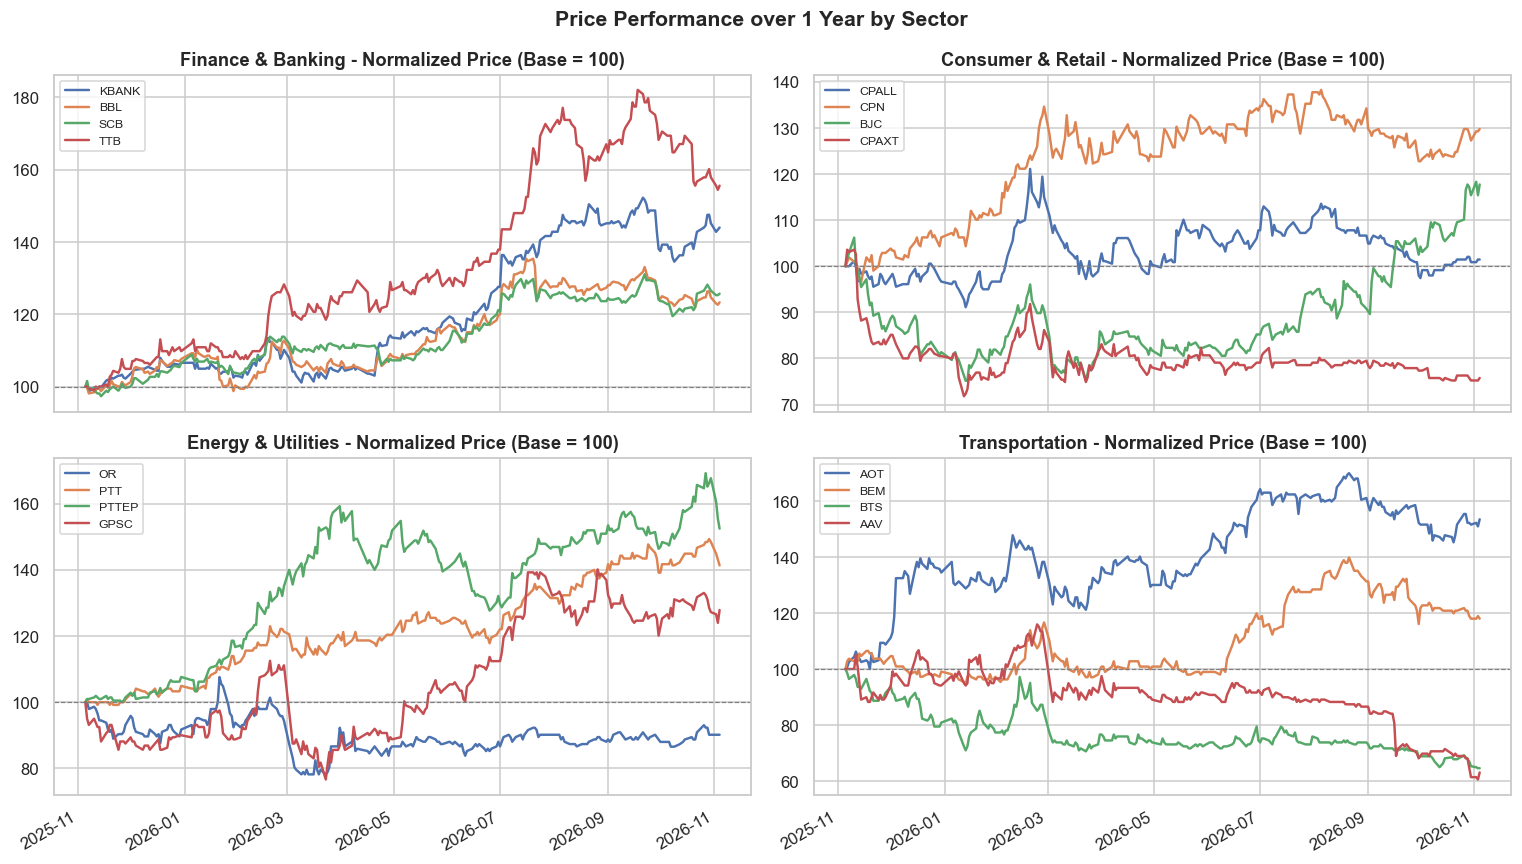

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)        # สร้างกราฟ 2x2 ช่อง (1 ช่องต่อ 1 กลุ่ม)
for ax, (sector, ts) in zip(axes.flat, SECTORS.items()):           # วนทีละกลุ่ม
    (prices[ts] / prices[ts].iloc[0] * 100).plot(ax=ax, lw=1.6)    # ปรับราคาวันแรกให้เป็น 100 จะได้เทียบกันได้
    ax.axhline(100, color="grey", ls="--", lw=0.8)                 # เส้นฐาน 100 ไว้ดูว่าขึ้นหรือลงจากจุดเริ่ม
    ax.set_title(f"{sector} - Normalized Price (Base = 100)", fontweight="bold")
    ax.set_xlabel(""); ax.legend(loc="upper left", fontsize=8)     # ซ่อนชื่อแกน x และใส่ legend
fig.suptitle("Price Performance over 1 Year by Sector", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()                                     # จัด layout ไม่ให้ทับกันแล้วแสดงกราฟ

**คำอธิบาย:** กราฟปรับฐานราคาเริ่มต้นเป็น 100 เพื่อเปรียบเทียบการเคลื่อนไหวของหุ้นที่มีระดับราคาต่างกันได้โดยตรง เส้นที่อยู่เหนือ 100 คือหุ้นที่ราคาสูงขึ้นในรอบ 1 ปี

---
## ภารกิจที่ 2: แสดงข้อมูลพื้นฐานและค่าสัดส่วนทางการเงินของหุ้นในแต่ละกลุ่มอุตสาหกรรม
ดึงจาก `yf.Ticker().info` (ราคา, EPS, BVPS, P/E, P/BV, ROE, Dividend) และ `financials` / `balance_sheet` (รายได้, กำไรสุทธิ, สินทรัพย์, หนี้สิน, ส่วนผู้ถือหุ้น)

In [5]:
# ฟังก์ชันช่วยดึงค่าจากงบการเงิน ถ้าไม่มีบรรทัดนั้นให้คืน NaN แทน (กันโค้ด error)
def safe_get(df, row, col=0):
    try:
        return float(df.loc[row].iloc[col])   # col=0 คือปีล่าสุด
    except Exception:
        return np.nan                         # หุ้นบางตัวไม่มีบางรายการในงบ

info_rows, fin_rows = [], []                  # list เก็บข้อมูลแต่ละหุ้น เดี๋ยวค่อยแปลงเป็น DataFrame
for t in TICKERS:
    tk = yf.Ticker(yf_sym(t))                 # สร้าง object ของหุ้นตัวนั้น
    info = tk.info                            # ข้อมูลพื้นฐาน + อัตราส่วนทางการเงิน
    info_rows.append({
        "Ticker": t, "Sector": SECTOR_OF[t],
        "Name": info.get("shortName"),                                        # ชื่อบริษัท
        "Price": info.get("currentPrice") or info.get("regularMarketPrice"),  # ราคาปัจจุบัน
        "MarketCap (THB bn)": (info.get("marketCap") or np.nan) / 1e9,        # มูลค่าตลาด หน่วยพันล้านบาท
        "EPS": info.get("trailingEps"),                                       # กำไรต่อหุ้น 12 เดือนล่าสุด
        "BVPS": info.get("bookValue"),                                        # มูลค่าทางบัญชีต่อหุ้น
        "P/E": info.get("trailingPE"),                                        # ราคา / กำไรต่อหุ้น
        "P/BV": info.get("priceToBook"),                                      # ราคา / มูลค่าทางบัญชี
        "ROE": info.get("returnOnEquity"),                                    # ผลตอบแทนต่อส่วนผู้ถือหุ้น
        "DPS": info.get("dividendRate") or 0.0,                               # เงินปันผลต่อหุ้น (ไม่มีให้เป็น 0)
        "Div Yield (%)": info.get("dividendYield") or 0.0,                    # อัตราเงินปันผลตอบแทน
        "D/E (%)": info.get("debtToEquity"),                                  # หนี้สิน / ส่วนผู้ถือหุ้น
    })
    fs, bs = tk.financials, tk.balance_sheet                                  # งบกำไรขาดทุน, งบดุล
    revenue, ni = safe_get(fs, "Total Revenue"), safe_get(fs, "Net Income")   # รายได้รวม, กำไรสุทธิ
    assets, equity = safe_get(bs, "Total Assets"), safe_get(bs, "Stockholders Equity")  # สินทรัพย์รวม, ส่วนผู้ถือหุ้น
    debt = safe_get(bs, "Total Debt")                                         # หนี้สินที่มีภาระดอกเบี้ย
    fin_rows.append({
        "Ticker": t, "Sector": SECTOR_OF[t],
        "Fiscal Year": fs.columns[0].year if len(fs.columns) else None,       # ปีงบการเงินล่าสุด
        "Revenue (THB bn)": revenue / 1e9, "Net Income (THB bn)": ni / 1e9,
        "Total Assets (THB bn)": assets / 1e9, "Equity (THB bn)": equity / 1e9,
        "Net Margin": ni / revenue,           # อัตรากำไรสุทธิ
        "ROA": ni / assets,                   # ผลตอบแทนต่อสินทรัพย์
        "ROE (FS)": ni / equity,              # ROE คำนวณเองจากงบ ไว้เทียบกับค่าใน info
        "Debt/Equity": debt / equity,         # อัตราส่วนหนี้ต่อทุน
    })

info_df = pd.DataFrame(info_rows).set_index("Ticker")   # แปลงเป็นตาราง ใช้ชื่อหุ้นเป็น index
fin_df = pd.DataFrame(fin_rows).set_index("Ticker")
# บางค่าจาก yfinance เป็น None แปลงให้เป็นตัวเลขทั้งหมดก่อน จะได้คำนวณต่อได้
for col in ["Price", "EPS", "BVPS", "P/E", "P/BV", "ROE", "DPS", "Div Yield (%)", "D/E (%)"]:
    info_df[col] = pd.to_numeric(info_df[col], errors="coerce")
info_df

,Sector,Name,Price,MarketCap (THB bn),EPS,BVPS,P/E,P/BV,ROE,DPS,Div Yield (%),D/E (%)
Ticker,,,,,,,,,,,,
KBANK,Finance & Banking,KBANK_KASIKORNBANK,247.0000,585.2239,21.5600,247.7620,11.4564,0.9969,0.0851,12.0000,4.9200,NaN
BBL,Finance & Banking,BBL_BANGKOK BANK,184.5000,352.1815,22.0200,308.3880,8.3787,0.5983,0.0648,10.0000,5.4600,NaN
SCB,Finance & Banking,SCB_SCB X,152.0000,511.8003,12.9200,143.8490,11.7647,1.0567,0.0873,11.2800,7.4500,NaN
TTB,Finance & Banking,TTB_TMBTHANACHART BANK,2.7000,236.3392,0.2400,2.5330,11.2500,1.0659,0.0906,0.1600,6.0000,NaN
CPALL,Consumer & Retail,CPALL_CP ALL,46.2500,412.1384,3.3600,14.7270,13.7649,3.1405,0.1038,1.6500,3.7500,131.2270
CPN,Consumer & Retail,CPN_CENTRAL PATTANA,66.2500,297.3300,4.4600,24.2750,14.8543,2.7291,0.1795,2.4000,3.6900,102.8600
BJC,Consumer & Retail,BJC_BERLI JUCKER,20.2000,80.9575,1.4600,29.2480,13.8356,0.6906,0.0552,0.5300,2.6400,141.3150
CPAXT,Consumer & Retail,CPAXT_CP AXTRA,14.5000,151.2011,0.8700,28.7250,16.6667,0.5048,0.0300,0.7100,5.0400,60.2150
OR,Energy & Utilities,OR_PTT OIL AND RETAIL BUSINESS,12.6000,151.2000,0.4400,9.1690,28.6364,1.3742,0.0477,0.6000,4.8000,39.4100


In [6]:
# แสดงสรุปงบการเงินแยกทีละกลุ่ม
for sector in SECTORS:
    print(f"\n===== {sector} : Financial Statement Summary (ล่าสุด) =====")
    display(fin_df[fin_df["Sector"] == sector].drop(columns="Sector").round(3))   # กรองเฉพาะกลุ่มนั้น


===== Finance & Banking : Financial Statement Summary (ล่าสุด) =====


,Fiscal Year,Revenue (THB bn),Net Income (THB bn),Total Assets (THB bn),Equity (THB bn),Net Margin,ROA,ROE (FS),Debt/Equity
Ticker,,,,,,,,,
KBANK,2025,207.4270,49.5650,"4,558.6180",581.1460,0.2390,0.0110,0.0850,0.3830
BBL,2025,190.9810,46.0070,"4,606.3420",573.9230,0.2410,0.0100,0.0800,0.9380
SCB,2025,182.5570,47.4880,"3,650.7420",495.3130,0.2600,0.0130,0.0960,0.7520
TTB,2025,72.4400,20.6390,"1,701.9660",244.1940,0.2850,0.0120,0.0850,0.4590



===== Consumer & Retail : Financial Statement Summary (ล่าสุด) =====


,Fiscal Year,Revenue (THB bn),Net Income (THB bn),Total Assets (THB bn),Equity (THB bn),Net Margin,ROA,ROE (FS),Debt/Equity
Ticker,,,,,,,,,
CPALL,2025,990.6630,28.2060,982.8140,138.1410,0.0280,0.0290,0.2040,3.2020
CPN,2025,50.0340,18.8410,302.6230,109.8810,0.3770,0.0620,0.1710,1.0620
BJC,2025,154.0200,4.0110,334.4910,120.3250,0.0260,0.0120,0.0330,1.3300
CPAXT,2025,517.8020,9.3560,576.6710,299.4570,0.0180,0.0160,0.0310,0.5750



===== Energy & Utilities : Financial Statement Summary (ล่าสุด) =====


,Fiscal Year,Revenue (THB bn),Net Income (THB bn),Total Assets (THB bn),Equity (THB bn),Net Margin,ROA,ROE (FS),Debt/Equity
Ticker,,,,,,,,,
OR,2025,658.7230,11.3040,197.9310,113.7580,0.0170,0.0570,0.0990,0.2070
PTT,2025,"2,662.1450",90.1660,"3,269.6600","1,127.4220",0.0340,0.0280,0.0800,0.8740
PTTEP,2025,281.4490,60.2730,933.9370,519.3050,0.2140,0.0650,0.1160,0.2440
GPSC,2025,84.9160,6.3990,264.2590,104.4060,0.0750,0.0240,0.0610,1.1030



===== Transportation : Financial Statement Summary (ล่าสุด) =====


,Fiscal Year,Revenue (THB bn),Net Income (THB bn),Total Assets (THB bn),Equity (THB bn),Net Margin,ROA,ROE (FS),Debt/Equity
Ticker,,,,,,,,,
AOT,2025,66.6790,18.1250,209.9320,130.8980,0.2720,0.0860,0.1380,0.3840
BEM,2025,16.9160,3.7810,160.5100,37.0010,0.2240,0.0240,0.1020,3.0380
BTS,2026,21.1290,-1.1520,322.2060,58.3920,-0.0550,-0.0040,-0.0200,3.2750
AAV,2025,45.6910,2.3360,76.3380,13.5560,0.0510,0.0310,0.1720,3.1720


ค่ามัธยฐานของอัตราส่วนทางการเงินรายอุตสาหกรรม (Sector Median)


,P/E,P/BV,ROE,Div Yield (%)
Sector,,,,
Consumer & Retail,14.3449,1.7099,0.0795,3.7200
Energy & Utilities,11.8851,1.1812,0.0829,5.4500
Finance & Banking,11.3532,1.0268,0.0862,5.7300
Transportation,35.8779,1.6847,0.0404,0.6700


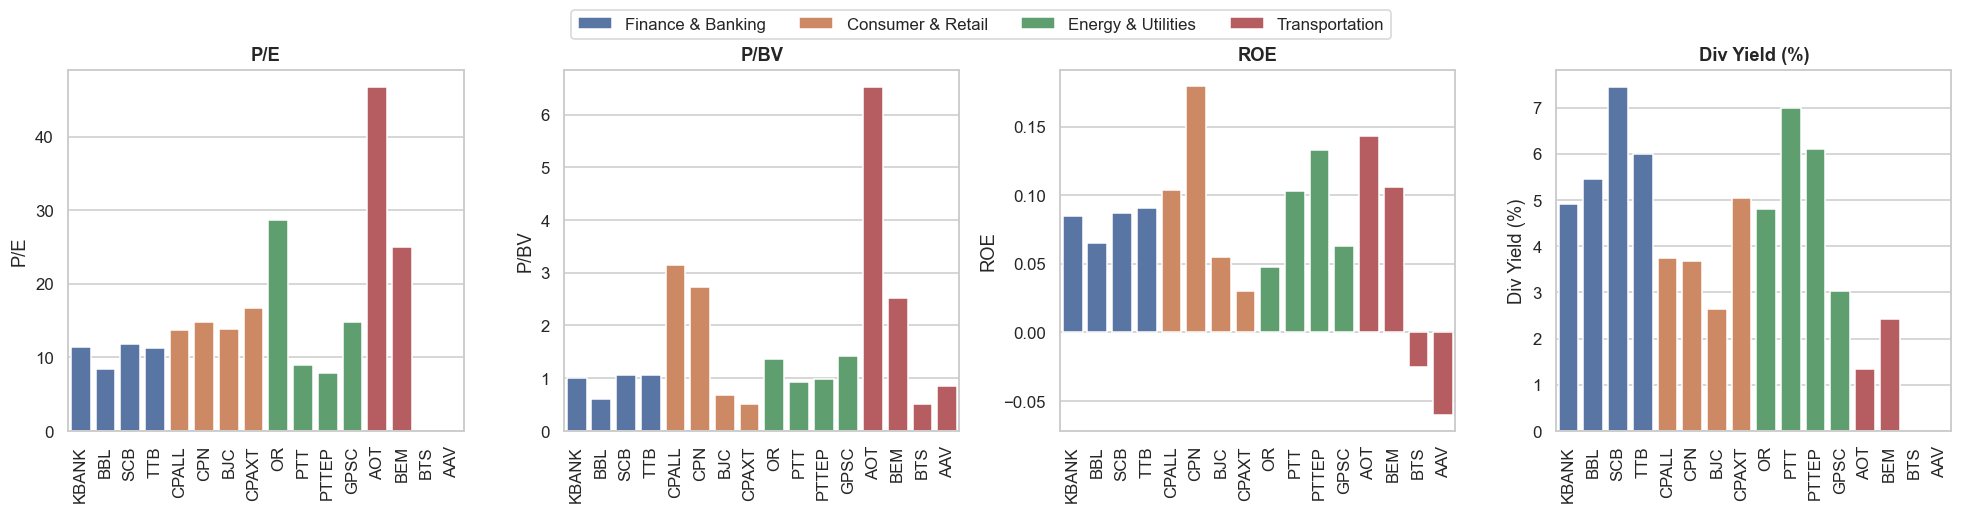

In [7]:
ratio_cols = ["P/E", "P/BV", "ROE", "Div Yield (%)"]                 # อัตราส่วนที่จะเทียบกัน
sector_avg = info_df.groupby("Sector")[ratio_cols].median()          # ใช้ median ของกลุ่ม (ทนต่อค่าโดดกว่า mean)
print("ค่ามัธยฐานของอัตราส่วนทางการเงินรายอุตสาหกรรม (Sector Median)")
display(sector_avg)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))                    # กราฟแท่ง 4 ช่อง ช่องละ 1 อัตราส่วน
for ax, col in zip(axes, ratio_cols):
    sns.barplot(data=info_df.reset_index(), x="Ticker", y=col, hue="Sector", dodge=False, ax=ax)  # สีแยกตามกลุ่ม
    ax.set_title(col, fontweight="bold"); ax.tick_params(axis="x", rotation=90); ax.set_xlabel("")
    ax.get_legend().remove()                                         # เอา legend ของแต่ละช่องออก
handles, labels = axes[0].get_legend_handles_labels()               # ใช้ legend ร่วมกันอันเดียวด้านบน
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.05))
plt.tight_layout(); plt.show()

**การตีความ:**
- **P/E** สูงสะท้อนว่านักลงทุนยอมจ่ายแพงต่อกำไร 1 บาท (คาดหวังการเติบโตสูง) ส่วน P/E ต่ำอาจหมายถึงหุ้นราคาถูกหรือมีความเสี่ยงสูง
- **P/BV < 1** หมายถึงราคาตลาดต่ำกว่ามูลค่าทางบัญชี พบมากในกลุ่มธนาคารเนื่องจาก ROE อยู่ในระดับต่ำกว่าต้นทุนส่วนของผู้ถือหุ้น
- **ROE** วัดความสามารถในการทำกำไรจากส่วนของผู้ถือหุ้น และ **Dividend Yield** วัดผลตอบแทนจากเงินปันผล
- หุ้นที่มี EPS ติดลบ (P/E ว่าง) แสดงว่าขาดทุนในรอบ 12 เดือนล่าสุด

---
## ภารกิจที่ 3: การประเมินมูลค่าที่แท้จริง (Intrinsic / Fair Value) แยกตามกลุ่มอุตสาหกรรม
ใช้หลายวิธีแล้วหาค่าเฉลี่ย เพื่อลดความลำเอียงของแบบจำลองใดแบบจำลองหนึ่ง

| วิธี | สูตร | ใช้กับ |
|---|---|---|
| **Graham Number** | $\sqrt{22.5 \times EPS \times BVPS}$ | หุ้นที่ไม่ใช่ธนาคาร และ EPS > 0 |
| **Justified P/BV** | $BVPS \times \dfrac{ROE - g}{K_e - g}$ | กลุ่มธนาคาร (มูลค่าผูกกับส่วนของผู้ถือหุ้น) |
| **Relative P/E** | $EPS \times$ Median P/E ของอุตสาหกรรม | EPS > 0 |
| **Dividend Discount Model (Gordon)** | $\dfrac{D_0 (1+g)}{K_e - g}$ | หุ้นที่จ่ายปันผล |

**Fair Value** = ค่าเฉลี่ยของวิธีที่ใช้ได้ → **Margin of Safety** = (Fair Value − Price) / Fair Value
- Margin > 0 → **Undervalued** (ราคาต่ำกว่ามูลค่าที่แท้จริง)
- Margin ≤ 0 → **Overvalued** (ราคาสูงกว่ามูลค่าที่แท้จริง)

In [8]:
# P/E กลางของแต่ละกลุ่ม (เอาเฉพาะหุ้นที่กำไร P/E > 0) ไว้ใช้ในวิธี Relative P/E
sector_pe = info_df[info_df["P/E"] > 0].groupby("Sector")["P/E"].median()

def fair_value(row):
    eps, bvps, roe, dps = row["EPS"], row["BVPS"], row["ROE"], row["DPS"]
    m = {}                                                        # เก็บ fair value ของแต่ละวิธี
    if row["Sector"] == "Finance & Banking":
        if pd.notna(roe) and pd.notna(bvps):
            m["Justified P/BV"] = bvps * (roe - G) / (KE - G)    # ธนาคารใช้ P/BV ที่สมเหตุสมผลตาม ROE
    elif pd.notna(eps) and eps > 0 and pd.notna(bvps) and bvps > 0:
        m["Graham Number"] = np.sqrt(22.5 * eps * bvps)          # สูตร Graham (ใช้ได้เฉพาะตอนกำไรเป็นบวก)
    if pd.notna(eps) and eps > 0:
        m["Relative P/E"] = eps * sector_pe[row["Sector"]]       # ถ้าซื้อขายที่ P/E เท่าค่ากลางของกลุ่ม ราคาควรเป็นเท่าไหร่
    if pd.notna(dps) and dps > 0:
        m["DDM"] = dps * (1 + G) / (KE - G)                      # Gordon Growth Model (เฉพาะหุ้นที่จ่ายปันผล)
    return pd.Series(m)

methods = info_df.apply(fair_value, axis=1)                       # คำนวณทุกวิธีให้ทุกหุ้น
val_df = info_df[["Sector", "Price"]].join(methods)               # รวมราคาปัจจุบันกับ fair value แต่ละวิธี
val_df["Fair Value"] = methods.mean(axis=1)                       # เฉลี่ยทุกวิธีที่คำนวณได้ (NaN ไม่นับ)
val_df["Margin of Safety"] = (val_df["Fair Value"] - val_df["Price"]) / val_df["Fair Value"]   # ส่วนลดจาก fair value
val_df["Status"] = np.where(val_df["Margin of Safety"] > 0, "Undervalued", "Overvalued")      # บวก = ถูก, ลบ = แพง
val_df.loc[val_df["Fair Value"].isna(), "Status"] = "N/A (ขาดทุน/ไม่มีปันผล)"                # หุ้นที่คำนวณไม่ได้เลย

# แสดงผลแยกตามกลุ่ม
for sector in SECTORS:
    print(f"\n===== {sector} =====")
    display(val_df[val_df["Sector"] == sector].drop(columns="Sector").round(2))


===== Finance & Banking =====


,Price,DDM,Graham Number,Justified P/BV,Relative P/E,Fair Value,Margin of Safety,Status
Ticker,,,,,,,,
KBANK,247.0000,206.0000,NaN,227.3600,244.7800,226.0500,-0.0900,Overvalued
BBL,184.5000,171.6700,NaN,179.0700,250.0000,200.2400,0.0800,Undervalued
SCB,152.0000,193.6400,NaN,137.3300,146.6800,159.2200,0.0500,Undervalued
TTB,2.7000,2.7500,NaN,2.5600,2.7200,2.6800,-0.0100,Overvalued



===== Consumer & Retail =====


,Price,DDM,Graham Number,Justified P/BV,Relative P/E,Fair Value,Margin of Safety,Status
Ticker,,,,,,,,
CPALL,46.2500,28.3300,33.3700,NaN,48.2000,36.6300,-0.2600,Overvalued
CPN,66.2500,41.2000,49.3600,NaN,63.9800,51.5100,-0.2900,Overvalued
BJC,20.2000,9.1000,31.0000,NaN,20.9400,20.3500,0.0100,Undervalued
CPAXT,14.5000,12.1900,23.7100,NaN,12.4800,16.1300,0.1000,Undervalued



===== Energy & Utilities =====


,Price,DDM,Graham Number,Justified P/BV,Relative P/E,Fair Value,Margin of Safety,Status
Ticker,,,,,,,,
OR,12.6000,10.3000,9.5300,NaN,5.2300,8.3500,-0.5100,Overvalued
PTT,39.0000,48.0700,64.0900,NaN,51.4600,54.5400,0.2800,Undervalued
PTTEP,142.0000,157.0800,240.9100,NaN,213.3400,203.7800,0.3000,Undervalued
GPSC,53.0000,25.7500,54.9900,NaN,42.6700,41.1400,-0.2900,Overvalued



===== Transportation =====


,Price,DDM,Graham Number,Justified P/BV,Relative P/E,Fair Value,Margin of Safety,Status
Ticker,,,,,,,,
AOT,61.2500,13.9000,16.6400,NaN,47.0000,25.8500,-1.3700,Overvalued
BEM,6.2500,2.5800,3.7400,NaN,8.9700,5.0900,-0.2300,Overvalued
BTS,1.8400,NaN,NaN,NaN,NaN,NaN,NaN,N/A (ขาดทุน/ไม่มีปันผล)
AAV,0.8000,NaN,NaN,NaN,NaN,NaN,NaN,N/A (ขาดทุน/ไม่มีปันผล)


---
## ภารกิจที่ 4: กราฟเปรียบเทียบ Market Price กับ Fair Value (แยกตามกลุ่มอุตสาหกรรม)

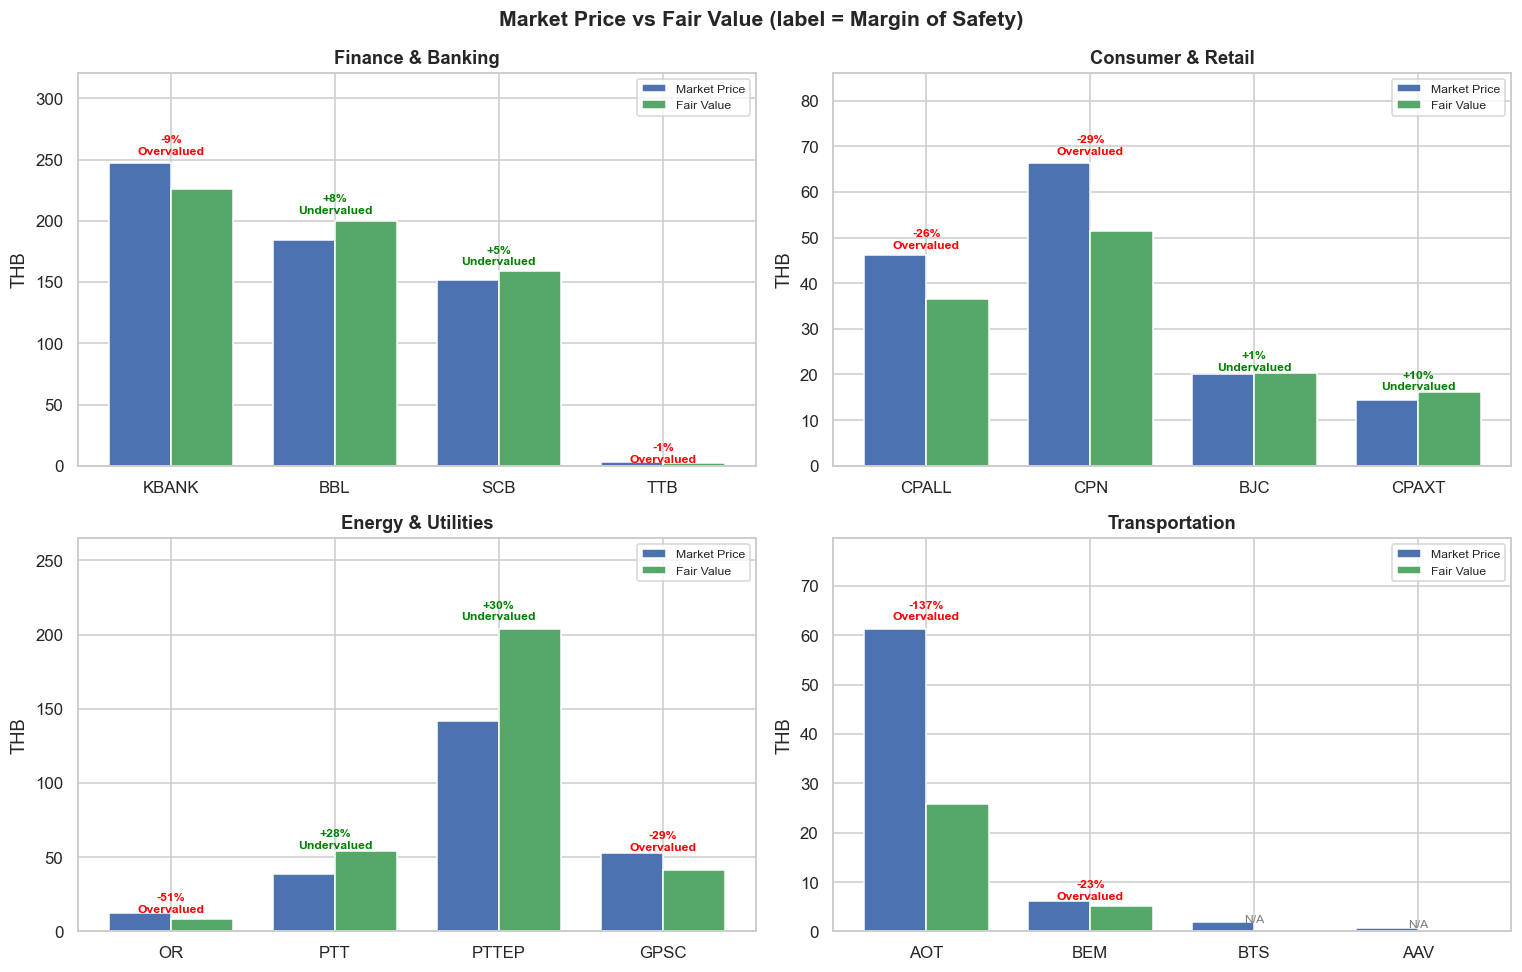

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))                              # 2x2 ช่อง ช่องละ 1 กลุ่ม
for ax, (sector, ts) in zip(axes.flat, SECTORS.items()):
    d = val_df.loc[ts]                                                       # ข้อมูลเฉพาะหุ้นในกลุ่มนี้
    x = np.arange(len(ts)); w = 0.38                                         # ตำแหน่งแท่ง และความกว้างแท่ง
    ax.bar(x - w/2, d["Price"], w, label="Market Price", color="#4C72B0")    # แท่งซ้าย = ราคาตลาด
    ax.bar(x + w/2, d["Fair Value"].fillna(0), w, label="Fair Value", color="#55A868")   # แท่งขวา = fair value
    for i, (_, r) in enumerate(d.iterrows()):                                # ใส่ป้าย % ส่วนต่างบนแท่ง
        if pd.notna(r["Margin of Safety"]):
            color = "green" if r["Margin of Safety"] > 0 else "red"          # เขียว = ถูก, แดง = แพง
            top = max(r["Price"], r["Fair Value"])                           # วางป้ายเหนือแท่งที่สูงกว่า
            ax.text(i, top * 1.03, f"{r['Margin of Safety']:+.0%}\n{r['Status']}", ha="center",
                    fontsize=8, color=color, fontweight="bold")
        else:
            ax.text(i, r["Price"] * 1.03, "N/A", ha="center", fontsize=8, color="grey")   # หุ้นที่ประเมินไม่ได้
    ax.set_xticks(x, ts); ax.set_ylabel("THB")
    ax.set_ylim(0, max(d["Price"].max(), d["Fair Value"].max()) * 1.3)     # เผื่อที่ด้านบนให้ป้ายไม่ล้น
    ax.set_title(sector, fontweight="bold"); ax.legend(fontsize=8)
fig.suptitle("Market Price vs Fair Value (label = Margin of Safety)", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

---
## ภารกิจที่ 5: คำนวณ Simple Return, Log Return, Expected Return และ Annualized Return

| ตัวชี้วัด | สูตร |
|---|---|
| Simple Return | $R_t = \dfrac{P_t - P_{t-1}}{P_{t-1}}$ |
| Log Return | $r_t = \ln\left(\dfrac{P_t}{P_{t-1}}\right)$ |
| Expected Return (รายวัน) | $E[R] = \bar{R} = \dfrac{1}{n}\sum R_t$ |
| Annualized Return (Arithmetic) | $E[R] \times 252$ |
| Annualized Return (Geometric / CAGR) | $\left(\dfrac{P_T}{P_0}\right)^{252/n} - 1$ |

In [10]:
simple_ret = prices.pct_change().dropna()               # Simple return รายวัน = (P_t / P_t-1) - 1
log_ret = np.log(prices / prices.shift(1)).dropna()     # Log return รายวัน = ln(P_t / P_t-1)
n_days = len(simple_ret)                                # จำนวนวันที่มีผลตอบแทน

ret_df = pd.DataFrame({
    "Sector": pd.Series(SECTOR_OF),
    "Mean Simple Return (daily)": simple_ret.mean(),                 # ค่าเฉลี่ย simple return ต่อวัน
    "Mean Log Return (daily)": log_ret.mean(),                       # ค่าเฉลี่ย log return ต่อวัน
    "Expected Return (daily)": simple_ret.mean(),                    # expected return = ค่าเฉลี่ยในอดีต
    "Annualized Return (arith.)": simple_ret.mean() * TRADING_DAYS,  # แปลงเป็นต่อปี (คูณ 252)
    "Annualized Log Return": log_ret.mean() * TRADING_DAYS,          # log return ต่อปี
    "CAGR (geometric)": (prices.iloc[-1] / prices.iloc[0]) ** (TRADING_DAYS / n_days) - 1,   # อัตราเติบโตทบต้นจริง
}).loc[TICKERS]                                                      # เรียงลำดับหุ้นตามกลุ่ม
print("ตัวอย่าง Simple Return รายวัน 5 วันล่าสุด"); display(simple_ret.tail())
print("ตัวอย่าง Log Return รายวัน 5 วันล่าสุด"); display(log_ret.tail())
ret_df

ตัวอย่าง Simple Return รายวัน 5 วันล่าสุด


Ticker,KBANK,BBL,SCB,TTB,CPALL,CPN,BJC,CPAXT,OR,PTT,PTTEP,GPSC,AOT,BEM,BTS,AAV
Date,,,,,,,,,,,,,,,,
2026-10-29,0.0000,0.0000,-0.0065,0.0072,0.0000,-0.0077,-0.0050,-0.0070,-0.0234,0.0060,0.0062,-0.0197,0.0000,-0.0157,-0.0105,-0.0494
2026-10-30,-0.0160,-0.0133,-0.0065,-0.0144,-0.0113,-0.0116,-0.0150,-0.0071,0.0000,-0.0059,0.0092,-0.0101,-0.0042,-0.0080,-0.0265,-0.0519
2026-11-02,-0.0163,-0.0135,-0.0098,-0.0146,0.0000,0.0157,0.0254,0.0000,0.0000,-0.0238,-0.0424,-0.0051,0.0042,0.0000,-0.0054,0.0000
2026-11-03,0.0041,-0.0027,0.0000,-0.0074,0.0057,0.0000,-0.0248,0.0000,0.0000,-0.0122,-0.0316,-0.0204,-0.0083,0.0081,-0.0055,-0.0137
2026-11-04,0.0041,0.0055,0.0033,0.0075,0.0000,0.0039,0.0203,0.0071,0.0000,-0.0123,-0.0196,0.0312,0.0168,-0.0080,0.0000,0.0417


ตัวอย่าง Log Return รายวัน 5 วันล่าสุด


Ticker,KBANK,BBL,SCB,TTB,CPALL,CPN,BJC,CPAXT,OR,PTT,PTTEP,GPSC,AOT,BEM,BTS,AAV
Date,,,,,,,,,,,,,,,,
2026-10-29,0.0000,0.0000,-0.0065,0.0072,0.0000,-0.0077,-0.0050,-0.0071,-0.0237,0.0059,0.0061,-0.0199,0.0000,-0.0159,-0.0105,-0.0506
2026-10-30,-0.0161,-0.0134,-0.0065,-0.0145,-0.0114,-0.0117,-0.0151,-0.0071,0.0000,-0.0059,0.0091,-0.0101,-0.0042,-0.0080,-0.0268,-0.0533
2026-11-02,-0.0164,-0.0136,-0.0099,-0.0147,0.0000,0.0156,0.0251,0.0000,0.0000,-0.0241,-0.0434,-0.0051,0.0042,0.0000,-0.0054,0.0000
2026-11-03,0.0041,-0.0027,0.0000,-0.0074,0.0057,0.0000,-0.0251,0.0000,0.0000,-0.0123,-0.0322,-0.0206,-0.0084,0.0080,-0.0055,-0.0138
2026-11-04,0.0041,0.0055,0.0033,0.0074,0.0000,0.0039,0.0201,0.0071,0.0000,-0.0124,-0.0198,0.0308,0.0167,-0.0080,0.0000,0.0408


,Sector,Mean Simple Return (daily),Mean Log Return (daily),Expected Return (daily),Annualized Return (arith.),Annualized Log Return,CAGR (geometric)
KBANK,Finance & Banking,0.0016,0.0015,0.0016,0.4035,0.3827,0.4662
BBL,Finance & Banking,0.0010,0.0009,0.0010,0.2412,0.2199,0.2460
SCB,Finance & Banking,0.0010,0.0010,0.0010,0.2528,0.2400,0.2713
TTB,Finance & Banking,0.0020,0.0018,0.0020,0.4955,0.4640,0.5904
CPALL,Consumer & Retail,0.0002,0.0001,0.0002,0.0450,0.0152,0.0153
CPN,Consumer & Retail,0.0012,0.0011,0.0012,0.3028,0.2736,0.3148
BJC,Consumer & Retail,0.0009,0.0007,0.0009,0.2248,0.1714,0.1870
CPAXT,Consumer & Retail,-0.0010,-0.0012,-0.0010,-0.2465,-0.2916,-0.2530
OR,Energy & Utilities,-0.0003,-0.0004,-0.0003,-0.0678,-0.1088,-0.1031
PTT,Energy & Utilities,0.0015,0.0014,0.0015,0.3822,0.3633,0.4381


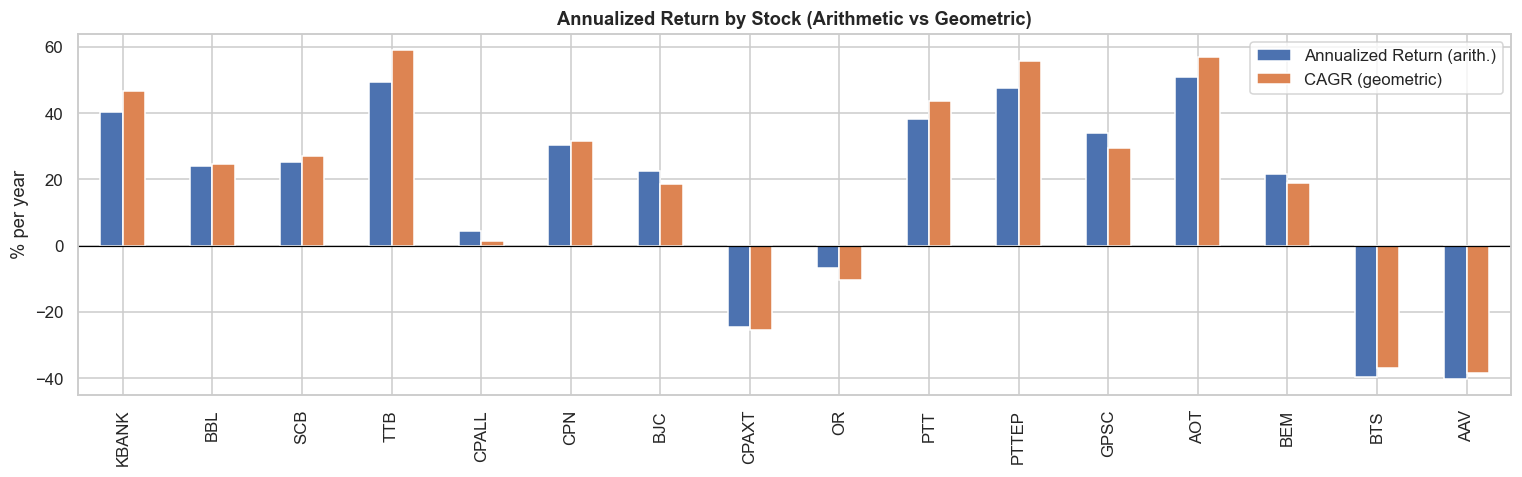

In [11]:
fig, ax = plt.subplots(figsize=(14, 4.5))
plot = ret_df[["Annualized Return (arith.)", "CAGR (geometric)"]].mul(100)   # แปลงเป็น % ก่อนพล็อต
plot.plot.bar(ax=ax, color=["#4C72B0", "#DD8452"])                          # กราฟแท่งเทียบ 2 แบบ
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("% per year")           # เส้น 0 ไว้แยกบวก/ลบ
ax.set_title("Annualized Return by Stock (Arithmetic vs Geometric)", fontweight="bold")
plt.tight_layout(); plt.show()

**การตีความ:** ผลตอบแทนแบบ Arithmetic สูงกว่า Geometric (CAGR) เสมอเมื่อราคามีความผันผวน เนื่องจาก *volatility drag* ($\approx \sigma^2/2$) — หุ้นที่ผันผวนสูงจะมีช่องว่างระหว่างสองค่านี้มาก Log Return มีคุณสมบัติบวกกันข้ามเวลาได้ จึงเหมาะกับการวิเคราะห์เชิงสถิติ ส่วน Simple Return บวกกันข้ามสินทรัพย์ได้ จึงใช้ในการคำนวณผลตอบแทนพอร์ต

---
## ภารกิจที่ 6: ประเมินความเสี่ยง — Volatility, Coefficient of Variation (CV) และ Sharpe Ratio

| ตัวชี้วัด | สูตร | ความหมาย |
|---|---|---|
| Annualized Volatility | $\sigma_{daily} \times \sqrt{252}$ | ความผันผวนของผลตอบแทน |
| Coefficient of Variation | $CV = \sigma / \mu$ | ความเสี่ยงต่อผลตอบแทน 1 หน่วย (ต่ำ = ดี; ใช้ได้เมื่อ μ > 0) |
| Sharpe Ratio | $\dfrac{E[R_p] - R_f}{\sigma_p}$ | ผลตอบแทนส่วนเกินต่อความเสี่ยง 1 หน่วย (สูง = ดี) |

In [12]:
# เริ่มจากตารางผลตอบแทนต่อปี แล้วเติมคอลัมน์ความเสี่ยงเข้าไป
risk_df = ret_df[["Sector", "Annualized Return (arith.)"]].rename(columns={"Annualized Return (arith.)": "Ann. Return"})
risk_df["Daily Volatility"] = simple_ret.std()                                  # SD ของผลตอบแทนรายวัน
risk_df["Ann. Volatility"] = simple_ret.std() * np.sqrt(TRADING_DAYS)           # แปลงเป็นต่อปี (คูณ root 252)
risk_df["CV"] = risk_df["Ann. Volatility"] / risk_df["Ann. Return"]             # ความเสี่ยงต่อผลตอบแทน 1 หน่วย
risk_df.loc[risk_df["Ann. Return"] <= 0, "CV"] = np.nan   # CV ไม่มีความหมายเมื่อผลตอบแทนเฉลี่ยติดลบ
risk_df["Sharpe Ratio"] = (risk_df["Ann. Return"] - RF) / risk_df["Ann. Volatility"]   # ผลตอบแทนส่วนเกิน / ความเสี่ยง
risk_df["Max Drawdown"] = (prices / prices.cummax() - 1).min()                  # ลดลงจากจุดสูงสุดมากที่สุดกี่ %
risk_df

,Sector,Ann. Return,Daily Volatility,Ann. Volatility,CV,Sharpe Ratio,Max Drawdown
KBANK,Finance & Banking,0.4035,0.0128,0.2034,0.5042,1.8850,-0.1163
BBL,Finance & Banking,0.2412,0.0130,0.2062,0.8546,1.0731,-0.1037
SCB,Finance & Banking,0.2528,0.0101,0.1597,0.6319,1.4574,-0.0886
TTB,Finance & Banking,0.4955,0.0158,0.2504,0.5055,1.8986,-0.1519
CPALL,Consumer & Retail,0.0450,0.0154,0.2452,5.4440,0.1021,-0.1972
CPN,Consumer & Retail,0.3028,0.0152,0.2420,0.7990,1.1690,-0.1119
BJC,Consumer & Retail,0.2248,0.0206,0.3274,1.4563,0.6256,-0.2926
CPAXT,Consumer & Retail,-0.2465,0.0188,0.2987,NaN,-0.8921,-0.3069
OR,Energy & Utilities,-0.0678,0.0181,0.2876,NaN,-0.3051,-0.2733
PTT,Energy & Utilities,0.3822,0.0122,0.1935,0.5064,1.8716,-0.0767


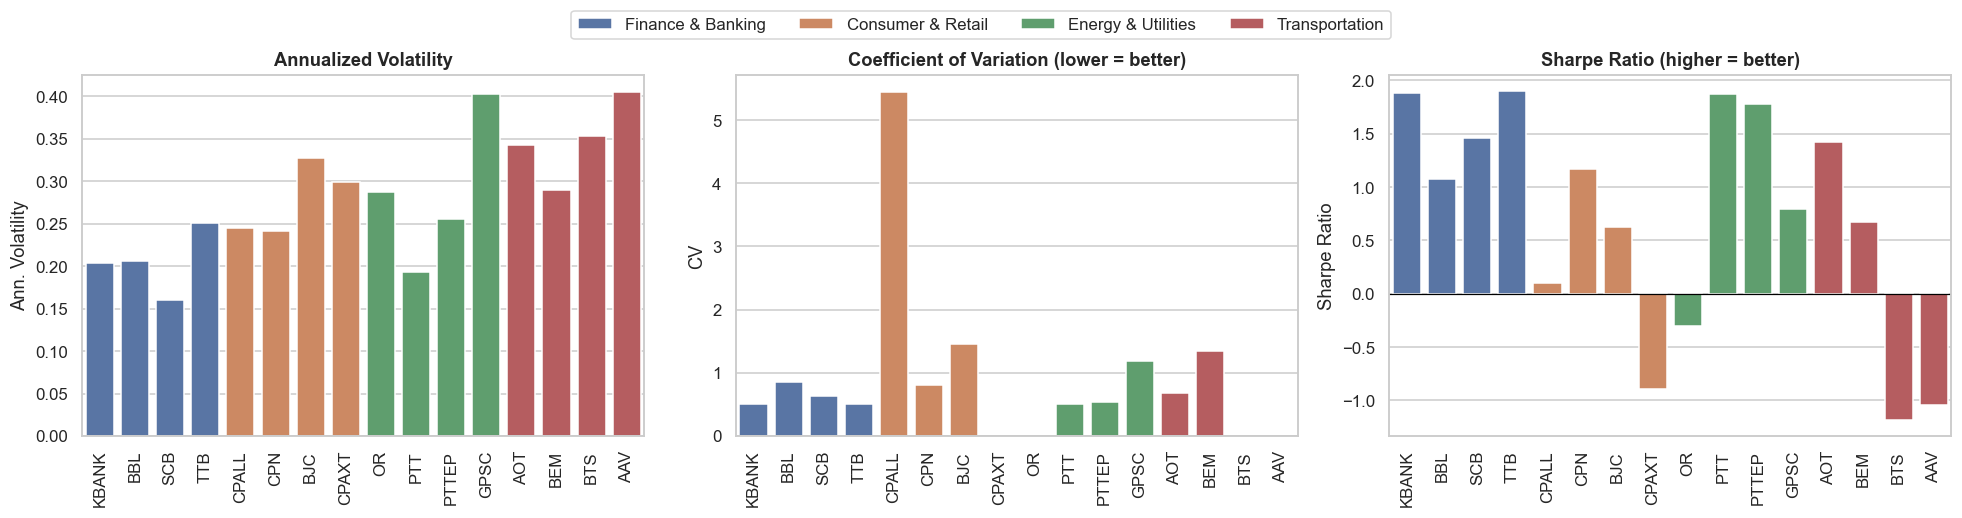

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))                  # 3 กราฟ: Vol, CV, Sharpe
for ax, col, title in zip(axes, ["Ann. Volatility", "CV", "Sharpe Ratio"],
                          ["Annualized Volatility", "Coefficient of Variation (lower = better)", "Sharpe Ratio (higher = better)"]):
    d = risk_df.reset_index().rename(columns={"index": "Ticker"})  # เอา index ออกมาเป็นคอลัมน์ Ticker ให้ seaborn ใช้
    sns.barplot(data=d, x="Ticker", y=col, hue="Sector", dodge=False, ax=ax)
    ax.set_title(title, fontweight="bold"); ax.tick_params(axis="x", rotation=90); ax.set_xlabel("")
    ax.axhline(0, color="black", lw=0.8); ax.get_legend().remove()
handles, labels = axes[0].get_legend_handles_labels()             # legend รวมด้านบน
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

---
## ภารกิจที่ 7: วิเคราะห์และจัดอันดับ "ผลตอบแทนต่อความเสี่ยง" ในแต่ละอุตสาหกรรมด้วย Scatter Plot
แกน X = Annualized Volatility, แกน Y = Annualized Return, ขนาดจุด/สี = Sharpe Ratio — หุ้นที่อยู่ **มุมซ้ายบน** (ผลตอบแทนสูง ความเสี่ยงต่ำ) ดีที่สุด เส้นประคือ Capital Allocation Line จาก RF ผ่านหุ้นที่ Sharpe สูงสุดในกลุ่ม

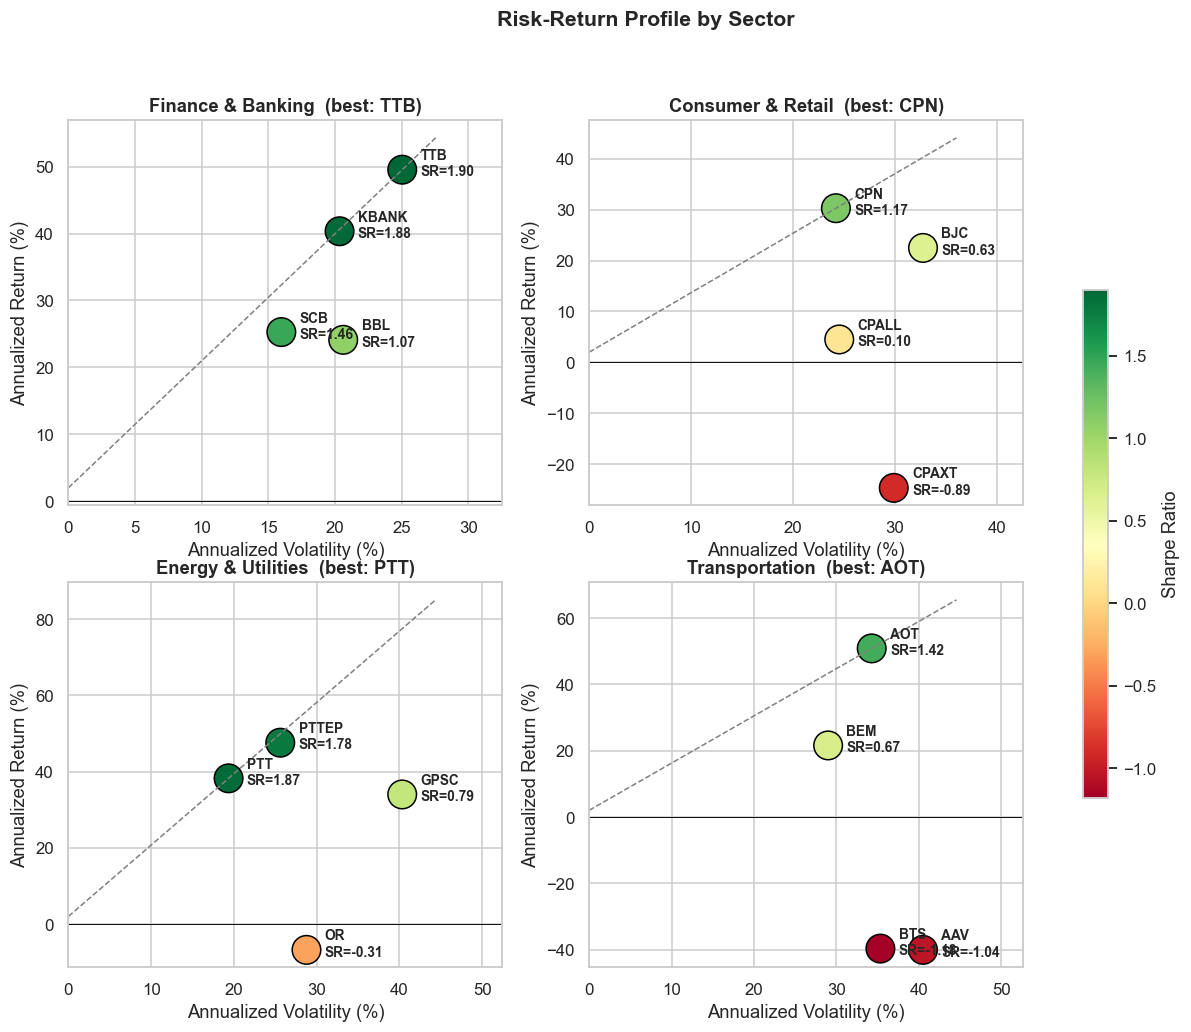

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (sector, ts) in zip(axes.flat, SECTORS.items()):
    d = risk_df.loc[ts]                                                        # หุ้นในกลุ่มนี้
    # scatter: x = ความเสี่ยง, y = ผลตอบแทน, สี = Sharpe (เขียว = ดี, แดง = แย่) ใช้สเกลสีเดียวกันทุกกลุ่ม
    sc = ax.scatter(d["Ann. Volatility"] * 100, d["Ann. Return"] * 100, c=d["Sharpe Ratio"],
                    cmap="RdYlGn", s=350, edgecolor="black", vmin=risk_df["Sharpe Ratio"].min(),
                    vmax=risk_df["Sharpe Ratio"].max())
    for t, r in d.iterrows():                                                  # ใส่ชื่อหุ้น + ค่า Sharpe ข้างจุด
        ax.annotate(f"{t}\nSR={r['Sharpe Ratio']:.2f}", (r["Ann. Volatility"] * 100, r["Ann. Return"] * 100),
                    textcoords="offset points", xytext=(12, -4), fontsize=9, fontweight="bold")
    best = d["Sharpe Ratio"].idxmax()                                          # หุ้น Sharpe สูงสุดในกลุ่ม
    xs = np.linspace(0, d["Ann. Volatility"].max() * 110, 50)
    ax.plot(xs, RF * 100 + d.loc[best, "Sharpe Ratio"] * xs, ls="--", color="grey", lw=1)   # เส้นจาก Rf ผ่านตัวที่ดีที่สุด
    ax.axhline(0, color="black", lw=0.6)                                       # เส้นผลตอบแทน 0%
    ax.set_xlim(0, d["Ann. Volatility"].max() * 130)
    ax.set_title(f"{sector}  (best: {best})", fontweight="bold")
    ax.set_xlabel("Annualized Volatility (%)"); ax.set_ylabel("Annualized Return (%)")
fig.colorbar(sc, ax=axes, shrink=0.6, label="Sharpe Ratio")                    # แถบสีบอกค่า Sharpe
fig.suptitle("Risk-Return Profile by Sector", fontsize=14, fontweight="bold")
plt.show()

In [15]:
rank_df = risk_df.copy()
# จัดอันดับ Sharpe ภายในกลุ่ม (1 = ดีที่สุด)
rank_df["Rank in Sector"] = rank_df.groupby("Sector")["Sharpe Ratio"].rank(ascending=False).astype(int)
rank_df = rank_df.sort_values(["Sector", "Rank in Sector"])      # เรียงตามกลุ่ม แล้วตามอันดับ
rank_df[["Sector", "Rank in Sector", "Ann. Return", "Ann. Volatility", "CV", "Sharpe Ratio"]]

,Sector,Rank in Sector,Ann. Return,Ann. Volatility,CV,Sharpe Ratio
CPN,Consumer & Retail,1,0.3028,0.2420,0.7990,1.1690
BJC,Consumer & Retail,2,0.2248,0.3274,1.4563,0.6256
CPALL,Consumer & Retail,3,0.0450,0.2452,5.4440,0.1021
CPAXT,Consumer & Retail,4,-0.2465,0.2987,NaN,-0.8921
PTT,Energy & Utilities,1,0.3822,0.1935,0.5064,1.8716
PTTEP,Energy & Utilities,2,0.4756,0.2559,0.5381,1.7802
GPSC,Energy & Utilities,3,0.3399,0.4033,1.1865,0.7932
OR,Energy & Utilities,4,-0.0678,0.2876,NaN,-0.3051
TTB,Finance & Banking,1,0.4955,0.2504,0.5055,1.8986
KBANK,Finance & Banking,2,0.4035,0.2034,0.5042,1.8850


---
## ภารกิจที่ 8: เลือกหุ้นตัวแทนจากแต่ละกลุ่ม (รวม 4 ตัว)
เกณฑ์ประกอบการตัดสินใจ: (1) อันดับ Sharpe Ratio ในกลุ่ม (2) สถานะ Under/Overvalued จากภารกิจที่ 3 (3) ขนาดและสภาพคล่อง (Market Cap) และ (4) ความสัมพันธ์ (correlation) ระหว่างหุ้นเพื่อการกระจายความเสี่ยง

In [16]:
auto_pick = rank_df[rank_df["Rank in Sector"] == 1].index.tolist()    # ตัวที่ได้อันดับ 1 ของแต่ละกลุ่ม
# รวมข้อมูลสำคัญจากทุกภารกิจไว้ในตารางเดียว ไว้ใช้ตัดสินใจ
summary = (risk_df[["Sector", "Ann. Return", "Ann. Volatility", "Sharpe Ratio"]]
           .join(val_df[["Price", "Fair Value", "Margin of Safety", "Status"]])
           .join(info_df[["MarketCap (THB bn)"]])
           .join(rank_df[["Rank in Sector"]]))
print("หุ้นที่ Sharpe Ratio สูงสุดในแต่ละกลุ่ม (เลือกอัตโนมัติ):", auto_pick)
print("หุ้นตัวแทนที่กลุ่มเลือกสร้างพอร์ต:", PORTFOLIO)
summary.loc[PORTFOLIO]    # ดูเฉพาะ 4 ตัวที่กลุ่มเลือก

หุ้นที่ Sharpe Ratio สูงสุดในแต่ละกลุ่ม (เลือกอัตโนมัติ): ['CPN', 'PTT', 'TTB', 'AOT']
หุ้นตัวแทนที่กลุ่มเลือกสร้างพอร์ต: ['KBANK', 'CPALL', 'OR', 'AOT']


,Sector,Ann. Return,Ann. Volatility,Sharpe Ratio,Price,Fair Value,Margin of Safety,Status,MarketCap (THB bn),Rank in Sector
KBANK,Finance & Banking,0.4035,0.2034,1.8850,247.0000,226.0460,-0.0927,Overvalued,585.2239,2
CPALL,Consumer & Retail,0.0450,0.2452,0.1021,46.2500,36.6304,-0.2626,Overvalued,412.1384,3
OR,Energy & Utilities,-0.0678,0.2876,-0.3051,12.6000,8.3523,-0.5086,Overvalued,151.2000,4
AOT,Transportation,0.5084,0.3429,1.4243,61.2500,25.8474,-1.3697,Overvalued,874.9991,1


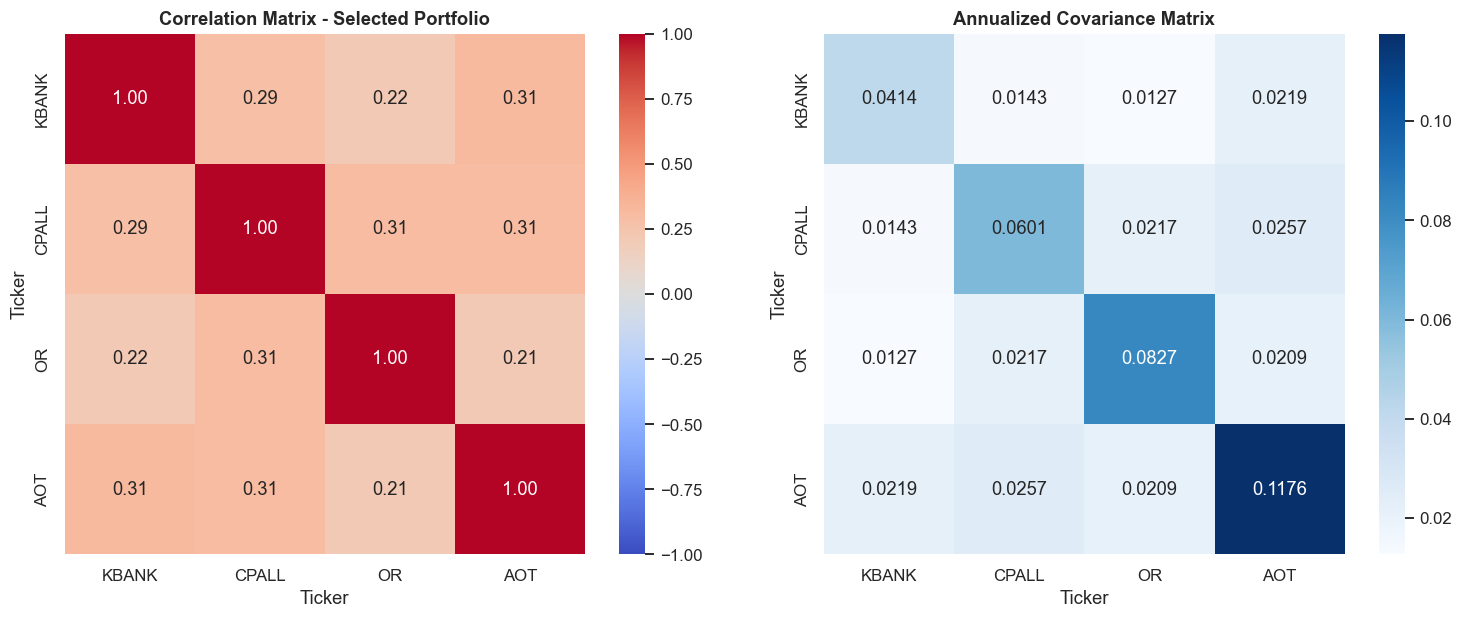

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
# heatmap correlation: ยิ่งต่ำยิ่งช่วยกระจายความเสี่ยงได้ดี
sns.heatmap(simple_ret[PORTFOLIO].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=axes[0], square=True)
axes[0].set_title("Correlation Matrix - Selected Portfolio", fontweight="bold")
# covariance ต่อปี (คูณ 252) ใช้เป็น input ของ MPT
sns.heatmap(simple_ret[PORTFOLIO].cov() * TRADING_DAYS, annot=True, fmt=".4f", cmap="Blues", ax=axes[1], square=True)
axes[1].set_title("Annualized Covariance Matrix", fontweight="bold")
plt.tight_layout(); plt.show()

---
## ภารกิจที่ 9: สร้างพอร์ตจำลองด้วย Modern Portfolio Theory (Markowitz Mean–Variance Optimization)
- ผลตอบแทนพอร์ต: $E[R_p] = w^\top \mu$
- ความเสี่ยงพอร์ต: $\sigma_p = \sqrt{w^\top \Sigma w}$
- เงื่อนไข: $\sum w_i = 1$, $0 \le w_i \le 1$ (ไม่มี Short selling)

หาพอร์ต 2 แบบด้วย `scipy.optimize.minimize` (SLSQP):
1. **Maximum Sharpe Ratio Portfolio (Tangency Portfolio)** — พอร์ตที่ดีที่สุดตาม MPT
2. **Global Minimum Variance Portfolio** — พอร์ตความเสี่ยงต่ำสุด

In [18]:
mu = simple_ret[PORTFOLIO].mean() * TRADING_DAYS     # expected return ต่อปีของแต่ละหุ้น
cov = simple_ret[PORTFOLIO].cov() * TRADING_DAYS     # covariance matrix ต่อปี
n = len(PORTFOLIO)                                   # จำนวนหุ้นในพอร์ต (4)

# ฟังก์ชันคำนวณ return, vol, sharpe ของพอร์ตจากน้ำหนัก w
def port_stats(w, mu=mu, cov=cov):
    r = float(w @ mu)                    # ผลตอบแทนพอร์ต = w·mu
    v = float(np.sqrt(w @ cov @ w))      # ความเสี่ยงพอร์ต = sqrt(w' Σ w)
    return r, v, (r - RF) / v            # คืนค่า return, vol, sharpe

bounds = [(0, 1)] * n                                           # น้ำหนักแต่ละตัว 0–100% (ห้าม short)
sum_to_one = {"type": "eq", "fun": lambda w: w.sum() - 1}       # บังคับให้น้ำหนักรวม = 100%
w0 = np.repeat(1 / n, n)                                        # จุดเริ่มต้น = ถือเท่ากัน 25% ทุกตัว

# หา Sharpe สูงสุด -> minimize ค่าลบของ Sharpe (scipy มีแต่ minimize)
max_sharpe = minimize(lambda w: -port_stats(w)[2], w0, method="SLSQP", bounds=bounds, constraints=[sum_to_one])
# หาความเสี่ยงต่ำสุด -> minimize vol ตรง ๆ
min_vol = minimize(lambda w: port_stats(w)[1], w0, method="SLSQP", bounds=bounds, constraints=[sum_to_one])

# ฟังก์ชันแปลงน้ำหนักเป็น 1 แถวของตารางสรุป
def portfolio_frame(weights, name):
    r, v, s = port_stats(weights)
    row = {f"Weight {t}": w for t, w in zip(PORTFOLIO, weights)}           # น้ำหนักแต่ละหุ้น
    row.update({"Expected Return": r, "Volatility": v, "Sharpe Ratio": s})
    return pd.Series(row, name=name)

# ตารางพอร์ตที่ดีที่สุด เทียบกับพอร์ตถือเท่ากัน
best_df = pd.DataFrame([
    portfolio_frame(max_sharpe.x, "Max Sharpe (Optimal)"),
    portfolio_frame(min_vol.x, "Min Volatility"),
    portfolio_frame(w0, "Equal Weight (benchmark)"),
])
# แสดงเป็น % ยกเว้น Sharpe ให้เป็นทศนิยม
best_df.style.format("{:.2%}", subset=[c for c in best_df.columns if c != "Sharpe Ratio"]).format("{:.3f}", subset=["Sharpe Ratio"])

,Weight KBANK,Weight CPALL,Weight OR,Weight AOT,Expected Return,Volatility,Sharpe Ratio
Max Sharpe (Optimal),74.44%,0.00%,0.00%,25.56%,43.03%,19.74%,2.079
Min Volatility,50.55%,25.82%,18.02%,5.61%,23.19%,16.77%,1.264
Equal Weight (benchmark),25.00%,25.00%,25.00%,25.00%,22.23%,18.31%,1.105


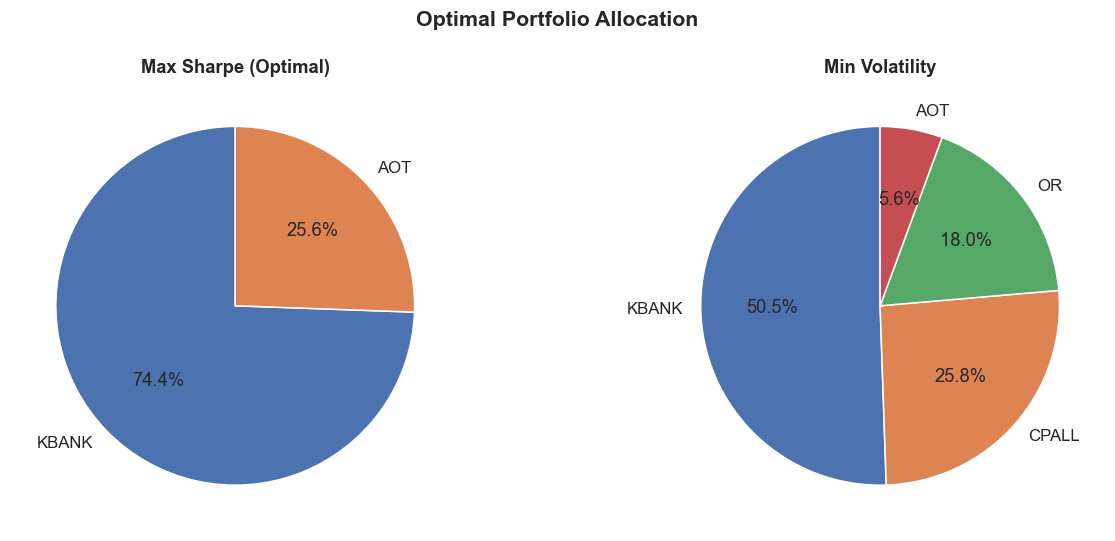

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, w) in zip(axes, [("Max Sharpe (Optimal)", max_sharpe.x), ("Min Volatility", min_vol.x)]):
    keep = w > 1e-4                                       # ตัดหุ้นที่น้ำหนักเกือบ 0 ออก ไม่งั้น label ทับกัน
    ax.pie(w[keep], labels=np.array(PORTFOLIO)[keep], autopct="%1.1f%%", startangle=90,
           colors=sns.color_palette("deep", n)[: keep.sum()], wedgeprops={"edgecolor": "white"})   # pie chart สัดส่วนพอร์ต
    ax.set_title(name, fontweight="bold")
fig.suptitle("Optimal Portfolio Allocation", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

---
## ภารกิจที่ 10: Monte Carlo Simulation (10,000 พอร์ต), Efficient Frontier และ Capital Market Line (CML)
- **Monte Carlo:** สุ่มน้ำหนัก 10,000 ชุด (Dirichlet distribution ทำให้ผลรวม = 1 และไม่ติดลบ) แล้วคำนวณ Return / Volatility / Sharpe ของแต่ละพอร์ต
- **Efficient Frontier:** สำหรับผลตอบแทนเป้าหมายแต่ละระดับ หาพอร์ตที่ความเสี่ยงต่ำสุด
- **CML:** $E[R] = R_f + \dfrac{E[R_T] - R_f}{\sigma_T}\,\sigma$ — เส้นตรงจาก RF ผ่าน Tangency Portfolio

In [20]:
rng = np.random.default_rng(SEED)                    # ตัวสุ่มเลข (fix seed)
W = rng.dirichlet(np.ones(n), N_SIMULATIONS)         # สุ่มน้ำหนัก 10,000 ชุด แต่ละชุดรวมกันได้ 1 พอดี
mc_ret = W @ mu.values                               # ผลตอบแทนของทุกพอร์ตพร้อมกัน
mc_vol = np.sqrt(np.einsum("ij,jk,ik->i", W, cov.values, W))   # ความเสี่ยงของทุกพอร์ต (w'Σw ทีละแถว)
mc_sharpe = (mc_ret - RF) / mc_vol                   # Sharpe ของทุกพอร์ต
mc_df = pd.DataFrame(W, columns=[f"Weight {t}" for t in PORTFOLIO])   # เก็บผลเป็นตาราง
mc_df["Expected Return"], mc_df["Volatility"], mc_df["Sharpe Ratio"] = mc_ret, mc_vol, mc_sharpe

print("Top 5 พอร์ตจาก Monte Carlo (เรียงตาม Sharpe Ratio)")
display(mc_df.sort_values("Sharpe Ratio", ascending=False).head())

# Efficient Frontier: ไล่ผลตอบแทนเป้าหมายตั้งแต่พอร์ต min vol ถึงหุ้นที่ return สูงสุด
targets = np.linspace(port_stats(min_vol.x)[0], mu.max(), 60)
frontier = []
for tr in targets:
    # ในแต่ละระดับผลตอบแทน หาพอร์ตที่ความเสี่ยงต่ำสุด (เพิ่ม constraint ว่า return ต้องเท่ากับ tr)
    res = minimize(lambda w: port_stats(w)[1], w0, method="SLSQP", bounds=bounds,
                   constraints=[sum_to_one, {"type": "eq", "fun": lambda w, tr=tr: w @ mu - tr}])
    if res.success:
        frontier.append((res.fun, tr))               # เก็บคู่ (vol, return) ไว้วาดเส้น
frontier = np.array(frontier)

Top 5 พอร์ตจาก Monte Carlo (เรียงตาม Sharpe Ratio)


,Weight KBANK,Weight CPALL,Weight OR,Weight AOT,Expected Return,Volatility,Sharpe Ratio
1899,0.7195,0.0056,0.0041,0.2708,0.4279,0.1972,2.0682
8130,0.7310,0.0174,0.0065,0.2451,0.4199,0.1945,2.0560
9041,0.6941,0.0154,0.0085,0.2820,0.4235,0.1967,2.0520
834,0.6808,0.0008,0.0154,0.3030,0.4277,0.1988,2.0507
7261,0.6757,0.0020,0.0197,0.3026,0.4252,0.1983,2.0437


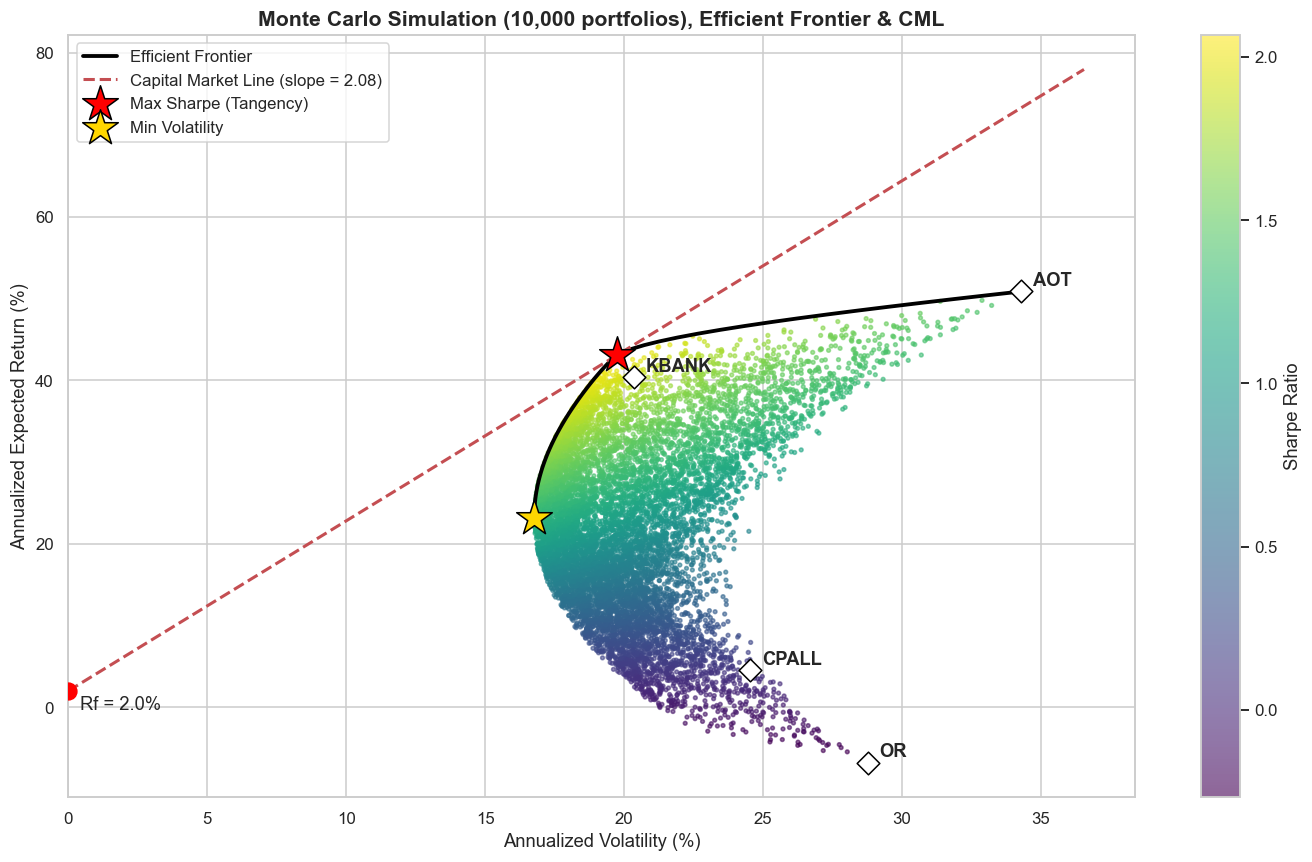

In [21]:
r_t, v_t, s_t = port_stats(max_sharpe.x)     # ค่าของพอร์ต Tangency (Max Sharpe)
r_m, v_m, _ = port_stats(min_vol.x)          # ค่าของพอร์ต Min Vol

fig, ax = plt.subplots(figsize=(13, 8))
sc = ax.scatter(mc_vol * 100, mc_ret * 100, c=mc_sharpe, cmap="viridis", s=6, alpha=0.6)   # จุด 10,000 พอร์ต สีตาม Sharpe
fig.colorbar(sc, label="Sharpe Ratio")
ax.plot(frontier[:, 0] * 100, frontier[:, 1] * 100, color="black", lw=2.5, label="Efficient Frontier")   # เส้น frontier
cml_x = np.linspace(0, max(mc_vol.max(), v_t) * 1.1, 50)
ax.plot(cml_x * 100, (RF + s_t * cml_x) * 100, "r--", lw=2, label=f"Capital Market Line (slope = {s_t:.2f})")   # CML: เริ่มที่ Rf ชันเท่า Sharpe สูงสุด
ax.scatter(v_t * 100, r_t * 100, marker="*", s=600, color="red", edgecolor="black", zorder=5, label="Max Sharpe (Tangency)")
ax.scatter(v_m * 100, r_m * 100, marker="*", s=600, color="gold", edgecolor="black", zorder=5, label="Min Volatility")
ax.scatter(0, RF * 100, marker="o", s=120, color="red", zorder=5)                                  # จุด Risk-free
ax.annotate(f"Rf = {RF:.1%}", (0, RF * 100), xytext=(8, -12), textcoords="offset points")
for t in PORTFOLIO:                                                                               # จุดหุ้นแต่ละตัว (ถือ 100%)
    ax.scatter(np.sqrt(cov.loc[t, t]) * 100, mu[t] * 100, marker="D", s=110, color="white", edgecolor="black", zorder=5)
    ax.annotate(t, (np.sqrt(cov.loc[t, t]) * 100, mu[t] * 100), xytext=(8, 4), textcoords="offset points", fontweight="bold")
ax.set_xlim(left=0)
ax.set_xlabel("Annualized Volatility (%)"); ax.set_ylabel("Annualized Expected Return (%)")
ax.set_title(f"Monte Carlo Simulation ({N_SIMULATIONS:,} portfolios), Efficient Frontier & CML", fontsize=14, fontweight="bold")
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

### เพิ่มเติม: มูลค่าความเสี่ยง (Value at Risk – VaR) และผลการทดสอบย้อนหลังของพอร์ต
- **Historical VaR (95%)**: ผลขาดทุนรายวันที่แย่ที่สุดที่ระดับเปอร์เซ็นไทล์ที่ 5 ของข้อมูลจริง
- **Parametric VaR (95%)**: $-(\mu_d - 1.645\,\sigma_d)$ โดยสมมติผลตอบแทนแจกแจงปกติ
- คิดเป็นเงินจากพอร์ตสมมติ 1,000,000 บาท

,Historical VaR 95% (1-day),Parametric VaR 95% (1-day),Historical VaR (THB),Parametric VaR (THB)
Max Sharpe,0.0170,0.0187,"17,030.4558","18,742.9268"
Min Volatility,0.0143,0.0165,"14,301.7293","16,453.2934"
Equal Weight,0.0166,0.0181,"16,635.7350","18,089.4085"


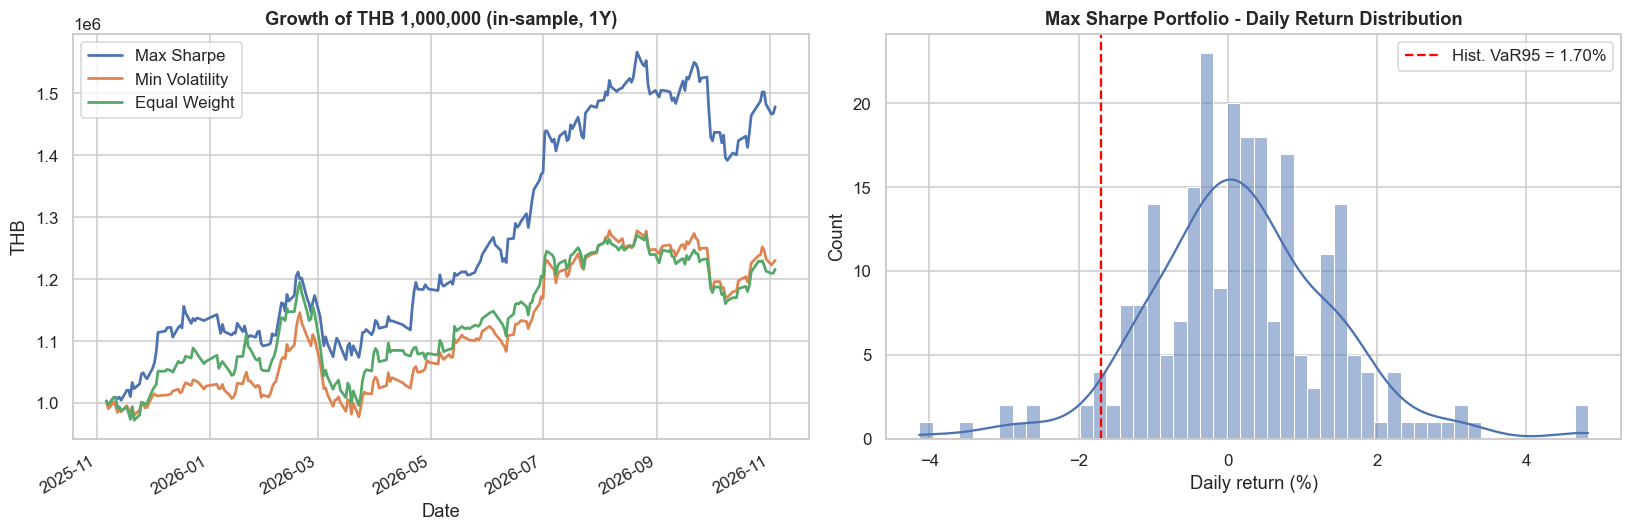

In [22]:
CAPITAL = 1_000_000                                   # สมมติเงินลงทุน 1 ล้านบาท
# ผลตอบแทนรายวันของแต่ละพอร์ต = ผลตอบแทนหุ้น x น้ำหนัก
port_daily = pd.DataFrame({
    "Max Sharpe": simple_ret[PORTFOLIO] @ max_sharpe.x,
    "Min Volatility": simple_ret[PORTFOLIO] @ min_vol.x,
    "Equal Weight": simple_ret[PORTFOLIO] @ w0,
})
z = norm.ppf(0.95)                                    # z ที่ความเชื่อมั่น 95% ≈ 1.645
var_df = pd.DataFrame({
    "Historical VaR 95% (1-day)": -port_daily.quantile(0.05),                      # percentile ที่ 5 ของข้อมูลจริง
    "Parametric VaR 95% (1-day)": -(port_daily.mean() - z * port_daily.std()),     # สมมติแจกแจงปกติ
})
var_df["Historical VaR (THB)"] = var_df["Historical VaR 95% (1-day)"] * CAPITAL    # แปลงเป็นจำนวนเงิน
var_df["Parametric VaR (THB)"] = var_df["Parametric VaR 95% (1-day)"] * CAPITAL
display(var_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
((1 + port_daily).cumprod() * CAPITAL).plot(ax=axes[0], lw=1.8)                     # เงินทบต้นรายวันของแต่ละพอร์ต
axes[0].set_title("Growth of THB 1,000,000 (in-sample, 1Y)", fontweight="bold"); axes[0].set_ylabel("THB")
sns.histplot(port_daily["Max Sharpe"] * 100, bins=50, kde=True, ax=axes[1], color="#4C72B0")   # histogram ผลตอบแทนรายวัน
axes[1].axvline(-var_df.loc["Max Sharpe", "Historical VaR 95% (1-day)"] * 100, color="red", ls="--",
                label=f"Hist. VaR95 = {var_df.loc['Max Sharpe', 'Historical VaR 95% (1-day)']:.2%}")   # เส้นแดง = จุด VaR
axes[1].set_title("Max Sharpe Portfolio - Daily Return Distribution", fontweight="bold")
axes[1].set_xlabel("Daily return (%)"); axes[1].legend()
plt.tight_layout(); plt.show()

### เปรียบเทียบ: พอร์ตที่กลุ่มเลือก vs พอร์ตจากหุ้น Sharpe สูงสุดของแต่ละกลุ่ม
ทดสอบว่าการเลือกหุ้นตามตัวชี้วัด Sharpe ล้วน ๆ ให้พอร์ตที่ดีกว่าหรือไม่

In [23]:
# ฟังก์ชันหาพอร์ต Max Sharpe สำหรับหุ้นชุดไหนก็ได้ (ไว้เทียบ 2 ชุด)
def optimal_for(tickers):
    m = simple_ret[tickers].mean() * TRADING_DAYS     # return ต่อปี
    c = simple_ret[tickers].cov() * TRADING_DAYS      # covariance ต่อปี
    k = len(tickers)
    res = minimize(lambda w: -(w @ m - RF) / np.sqrt(w @ c @ w), np.repeat(1 / k, k), method="SLSQP",
                   bounds=[(0, 1)] * k, constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}])
    r, v = res.x @ m, np.sqrt(res.x @ c @ res.x)      # return และ vol ของพอร์ตที่ได้
    return pd.Series({"Stocks": ", ".join(tickers),
                      "Weights": ", ".join(f"{t} {w:.0%}" for t, w in zip(tickers, res.x) if w > 1e-3),   # โชว์เฉพาะตัวที่มีน้ำหนัก
                      "Expected Return": r, "Volatility": v, "Sharpe Ratio": (r - RF) / v})

# เทียบพอร์ตที่กลุ่มเลือก กับพอร์ตที่เลือกตาม Sharpe อันดับ 1 ของแต่ละกลุ่ม
pd.DataFrame({"Group's Portfolio": optimal_for(PORTFOLIO), "Best-Sharpe Picks": optimal_for(auto_pick)}).T

,Stocks,Weights,Expected Return,Volatility,Sharpe Ratio
Group's Portfolio,"KBANK, CPALL, OR, AOT","KBANK 74%, AOT 26%",0.4303,0.1974,2.0788
Best-Sharpe Picks,"CPN, PTT, TTB, AOT","CPN 10%, PTT 43%, TTB 34%, AOT 13%",0.4285,0.1538,2.6559


---
## สรุปผลการวิเคราะห์ (Summary)

In [24]:
opt = best_df.loc["Max Sharpe (Optimal)"]     # ดึงแถวพอร์ตที่ดีที่สุดมาสรุป
print("=" * 70)
print("พอร์ตที่ดีที่สุดตาม MPT (Maximum Sharpe Ratio)")
for t in PORTFOLIO:                           # แสดงน้ำหนัก + สถานะมูลค่าของแต่ละหุ้น
    print(f"  {t:6s} ({SECTOR_OF[t]:20s}) น้ำหนัก {opt['Weight ' + t]:6.1%} | สถานะมูลค่า: {val_df.loc[t, 'Status']}")
print(f"  Expected Return : {opt['Expected Return']:.2%} ต่อปี")
print(f"  Volatility      : {opt['Volatility']:.2%} ต่อปี")
print(f"  Sharpe Ratio    : {opt['Sharpe Ratio']:.3f}")
print(f"  Hist. VaR 95%   : {var_df.loc['Max Sharpe', 'Historical VaR (THB)']:,.0f} บาท/วัน (จากเงินลงทุน {CAPITAL:,} บาท)")
print("=" * 70)

พอร์ตที่ดีที่สุดตาม MPT (Maximum Sharpe Ratio)
  KBANK  (Finance & Banking   ) น้ำหนัก  74.4% | สถานะมูลค่า: Overvalued
  CPALL  (Consumer & Retail   ) น้ำหนัก   0.0% | สถานะมูลค่า: Overvalued
  OR     (Energy & Utilities  ) น้ำหนัก   0.0% | สถานะมูลค่า: Overvalued
  AOT    (Transportation      ) น้ำหนัก  25.6% | สถานะมูลค่า: Overvalued
  Expected Return : 43.03% ต่อปี
  Volatility      : 19.74% ต่อปี
  Sharpe Ratio    : 2.079
  Hist. VaR 95%   : 17,030 บาท/วัน (จากเงินลงทุน 1,000,000 บาท)


### การตีความเชิงกลยุทธ์
> ตัวเลขด้านล่างอ้างอิงผลการรันวันที่ 6 พ.ย. 2569 (ข้อมูล 5 พ.ย. 2568 – 4 พ.ย. 2569) หากรันใหม่ตัวเลขจะเปลี่ยนตามข้อมูลล่าสุด

**1. มูลค่าที่แท้จริง (ภารกิจ 3–4)**
- หุ้นที่ราคาต่ำกว่ามูลค่าที่แท้จริง (Undervalued) ได้แก่ BBL, SCB, BJC, CPAXT, PTT และ PTTEP โดย PTT และ PTTEP มี Margin of Safety สูงสุด (~28–30%)
- หุ้นตัวแทนทั้ง 4 ตัวของกลุ่มอยู่ในสถานะ **Overvalued** โดยเฉพาะ **AOT** (P/E ≈ 47 เท่า เทียบ Fair Value ≈ 26 บาท) ซึ่งตลาดให้ราคาล่วงหน้ากับการฟื้นตัวของการท่องเที่ยวและการเติบโตของกำไร ขณะที่ Graham Number และ DDM ให้น้ำหนักกับกำไร/ปันผลปัจจุบัน จึงประเมินหุ้นเติบโตต่ำกว่าความเป็นจริง
- **OR** มีกำไรต่อหุ้นต่ำ (EPS 0.44 บาท, P/E ≈ 29 เท่า เทียบค่ากลางอุตสาหกรรม ≈ 12 เท่า) จึงถูกประเมินว่าแพง

**2. ผลตอบแทนต่อความเสี่ยง (ภารกิจ 5–7)**
- กลุ่มธนาคารแข็งแกร่งที่สุด — ทุกตัวมี Sharpe > 1 โดย KBANK (Sharpe 1.89) อยู่อันดับ 2 ของกลุ่ม ใกล้เคียง TTB (1.90) แต่มีความผันผวนต่ำกว่า
- AOT มีผลตอบแทนสูงสุดในกลุ่มขนส่ง (~51% ต่อปี) แต่มีความผันผวนสูง (~34%) ส่วน BTS และ AAV ขาดทุนทั้งในงบการเงินและราคา
- CPALL (Sharpe 0.10) และ OR (Sharpe −0.31) มีผลตอบแทนต่อความเสี่ยงต่ำที่สุดในกลุ่มของตน ค่า CV ของ CPALL สูงถึง 5.4 หมายถึงเสี่ยงสูงมากเมื่อเทียบกับผลตอบแทนที่ได้

**3. พอร์ตที่เหมาะสมที่สุดตาม MPT (ภารกิจ 9–10)**
- **Max Sharpe Portfolio:** KBANK 74.4% + AOT 25.6% → Expected Return 43.0%, Volatility 19.7%, **Sharpe 2.08** สูงกว่าพอร์ตถือเท่ากัน (Sharpe 1.11) เกือบ 2 เท่า
- Optimizer ให้น้ำหนัก CPALL และ OR เป็น 0% เพราะผลตอบแทนคาดหวังต่ำ/ติดลบ แม้ความสัมพันธ์ระหว่างหุ้นจะต่ำ (0.21–0.31) ซึ่งช่วยกระจายความเสี่ยงได้ก็ตาม
- **Min Volatility Portfolio** (KBANK 50.6%, CPALL 25.8%, OR 18.0%, AOT 5.6%) มีความเสี่ยงต่ำสุด 16.8% แต่ผลตอบแทนลดลงเหลือ 23.2% — เหมาะกับนักลงทุนที่รับความเสี่ยงได้ต่ำ
- ผลจาก Monte Carlo 10,000 พอร์ตสอดคล้องกับ Optimizer: พอร์ตที่ Sharpe สูงสุดจากการสุ่ม (~2.07) อยู่ใกล้จุด Tangency และไม่มีพอร์ตใดอยู่เหนือ Efficient Frontier
- VaR 95% รายวันของพอร์ต Max Sharpe ≈ 1.7% หรือประมาณ 17,000 บาทต่อเงินลงทุน 1 ล้านบาท

**4. ข้อเสนอแนะ**
- พอร์ต Max Sharpe กระจุกใน 2 หุ้น (ความเสี่ยงจากการกระจุกตัว) ในทางปฏิบัติควรกำหนดเพดานน้ำหนัก เช่น ไม่เกิน 40% ต่อหุ้น
- เมื่อเลือกตัวแทนตาม Sharpe สูงสุดของแต่ละกลุ่ม (CPN, PTT, TTB, AOT) พอร์ตได้ **Sharpe 2.66** และความผันผวนเพียง 15.4% ดีกว่าพอร์ตที่กลุ่มเลือก — ชี้ว่าการเปลี่ยน CPALL → CPN และ OR → PTT จะช่วยปรับปรุงพอร์ต โดย PTT ยังอยู่ในสถานะ Undervalued อีกด้วย

### ข้อจำกัดของการวิเคราะห์
1. ใช้ข้อมูลเพียง 1 ปี ค่าเฉลี่ยผลตอบแทนมีความคลาดเคลื่อนสูง (estimation error) และพอร์ต Max Sharpe จึงไวต่อข้อมูลช่วงเวลานี้มาก
2. ผลทดสอบย้อนหลังเป็น *in-sample* (ใช้ข้อมูลชุดเดียวกับที่ใช้หาน้ำหนัก) จึงไม่ใช่การพยากรณ์ผลตอบแทนในอนาคต
3. Fair Value ขึ้นกับสมมติฐาน $K_e$, $g$ และข้อมูลจาก yfinance ซึ่งอาจไม่ครบถ้วนสำหรับหุ้นไทย
4. ไม่ได้รวมค่าธรรมเนียมการซื้อขาย ภาษี และการปรับพอร์ต (rebalancing)